# Week 12 – Recent Retail Data and Future Forecasting

## Objective

Explore recent retail sales and inventory data from
2025–2026, evaluate the adaptability of the Random
Forest forecasting approach, and prepare data for
future forecasting and business recommendations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
sales_df = pd.read_csv(
    "../data/recent_retail/retail_sales_ml_apl.csv"
)

inventory_df = pd.read_csv(
    "../data/recent_retail/retail_inventory_ml_apl.csv"
)

print("Sales dataset:", sales_df.shape)
print("Inventory dataset:", inventory_df.shape)

Sales dataset: (125751, 17)
Inventory dataset: (284755, 18)


In [4]:
sales_df.head()

,Transaction Date,Sales Type,Is Return,Reason of Return,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Sales Channel,Qty Sold,Sales Amount,Cogs,Number of Transactions
0,2025-09-01,Full Price,0,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1.0,115.00,52.31,1
1,2025-09-07,Full Price,0,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1.0,115.00,58.47,1
2,2025-08-06,Promo,0,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1.0,79.99,43.76,1
3,2025-08-31,Full Price,0,NaN,Vendor 0246,PROD-140876,PROD-100419 SEG-500063 Scholar Footwear Boot C...,Scholar Footwear,Scholar Footwear Boot Collection,Scholar Footwear Boot Collection Woodland,SEG-500063 Scholar Footwear Boot Collection Wo...,STR-1234,Channel Alpha,1.0,110.00,50.60,1
4,2026-03-22,Full Price,0,NaN,Vendor 0169,PROD-166113,PROD-149345 SEG-511444 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Equilibrium,SEG-511444 Femme Footwear Trailblazer Equilibrium,STR-1157,Channel Alpha,1.0,160.00,77.95,1


In [5]:
inventory_df.head()

,Start Date,End Date,Stock Status,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Store Type,Sales Channel,Qty on hand,Stocks Selling Amount,Cost of Stocks,Stock Unit Selling Price,Stock Unit Cost Price
0,2025-08-07,2025-10-18,Full Price,Vendor 0255,PROD-159369,PROD-103395 SEG-500461 Scholar Footwear Canvas...,Scholar Footwear,Scholar Footwear Canvas Styles,Scholar Footwear Canvas Styles Drifter,SEG-500461 Scholar Footwear Canvas Styles Drifter,STR-1010,Retail Storefront,Channel Alpha,1,55.0,24.75,55.0,24.75
1,2026-02-15,2026-02-15,Full Price,Vendor 0010,PROD-180713,PROD-190644 SEG-520887 Femme Footwear Court Ca...,Femme Footwear,Femme Footwear Court Casual,Femme Footwear Court Casual Trident,SEG-520887 Femme Footwear Court Casual Trident,STR-1082,Retail Storefront,Channel Alpha,1,130.0,59.73,130.0,59.73
2,2026-01-08,2026-02-15,Full Price,Vendor 0166,PROD-169474,PROD-153439 SEG-512518 Femme Footwear Court Ca...,Femme Footwear,Femme Footwear Court Casual,Femme Footwear Court Casual Zephyr,SEG-512518 Femme Footwear Court Casual Zephyr,STR-1105,Retail Storefront,Channel Alpha,1,120.0,60.44,120.0,60.44
3,2025-12-23,2026-02-15,Full Price,Vendor 0106,PROD-170976,PROD-122029 SEG-504463 Junior Apparel Cozy Pul...,Junior Apparel,Junior Apparel Cozy Pullovers,Junior Apparel Cozy Pullovers Varied,SEG-504463 Junior Apparel Cozy Pullovers Varied,STR-1157,Retail Storefront,Channel Alpha,3,150.0,52.50,50.0,17.50
4,2026-02-10,9999-12-31,Full Price,Vendor 0134,PROD-183525,PROD-111954 SEG-502325 Scholar Footwear Modern...,Scholar Footwear,Scholar Footwear Modern Legend,Scholar Footwear Modern Legend Summit,SEG-502325 Scholar Footwear Modern Legend Summit,STR-1253,Retail Storefront,Channel Alpha,4,360.0,182.16,90.0,45.54


## 1. Exploratory Data Analysis

Inspect the dataset structure, data types, date ranges,
missing values and duplicate records before preprocessing.

In [6]:
print("Sales columns:")
print(sales_df.columns.tolist())

print("\nInventory columns:")
print(inventory_df.columns.tolist())

Sales columns:
['Transaction Date', 'Sales Type', 'Is Return', 'Reason of Return', 'Supplier', 'Product No', 'Product Description', 'Product Division', 'Product Category', 'Product Subcategory', 'Product Segment', 'Store', 'Sales Channel', 'Qty Sold', 'Sales Amount', 'Cogs', 'Number of Transactions']

Inventory columns:
['Start Date', 'End Date', 'Stock Status', 'Supplier', 'Product No', 'Product Description', 'Product Division', 'Product Category', 'Product Subcategory', 'Product Segment', 'Store', 'Store Type', 'Sales Channel', 'Qty on hand', 'Stocks Selling Amount', 'Cost of Stocks', 'Stock Unit Selling Price', 'Stock Unit Cost Price']


In [7]:
sales_df.info()
inventory_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125751 entries, 0 to 125750
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Transaction Date        125751 non-null  str    
 1   Sales Type              125751 non-null  str    
 2   Is Return               125751 non-null  int64  
 3   Reason of Return        0 non-null       float64
 4   Supplier                125751 non-null  str    
 5   Product No              125751 non-null  str    
 6   Product Description     125751 non-null  str    
 7   Product Division        125751 non-null  str    
 8   Product Category        125751 non-null  str    
 9   Product Subcategory     125751 non-null  str    
 10  Product Segment         125751 non-null  str    
 11  Store                   125751 non-null  str    
 12  Sales Channel           125751 non-null  str    
 13  Qty Sold                125751 non-null  float64
 14  Sales Amount            125751 

In [8]:
sales_df["Transaction Date"] = pd.to_datetime(
    sales_df["Transaction Date"], errors="coerce"
)

print("Earliest transaction:", sales_df["Transaction Date"].min())
print("Latest transaction:", sales_df["Transaction Date"].max())

print("\nNumber of stores:", sales_df["Store"].nunique())
print("Number of products:", sales_df["Product No"].nunique())
print("Number of unique dates:", sales_df["Transaction Date"].nunique())

Earliest transaction: 2025-06-01 00:00:00
Latest transaction: 2026-04-24 00:00:00

Number of stores: 40
Number of products: 2326
Number of unique dates: 326


In [9]:
print("Sales missing values:")
print(sales_df.isnull().sum())

print("\nInventory missing values:")
print(inventory_df.isnull().sum())

Sales missing values:
Transaction Date               0
Sales Type                     0
Is Return                      0
Reason of Return          125751
Supplier                       0
Product No                     0
Product Description            0
Product Division               0
Product Category               0
Product Subcategory            0
Product Segment                0
Store                          0
Sales Channel                  0
Qty Sold                       0
Sales Amount                   0
Cogs                           0
Number of Transactions         0
dtype: int64

Inventory missing values:
Start Date                  0
End Date                    0
Stock Status                0
Supplier                    0
Product No                  0
Product Description         0
Product Division            0
Product Category            0
Product Subcategory         0
Product Segment             0
Store                       0
Store Type                  0
Sales Channel    

In [10]:
print("Sales duplicate rows:", sales_df.duplicated().sum())
print("Inventory duplicate rows:", inventory_df.duplicated().sum())

Sales duplicate rows: 0
Inventory duplicate rows: 0


## 2. Data Validation and Preprocessing

Validate sales transactions, investigate product returns,
inspect promotion categories and identify potentially
invalid values before preparing the forecasting dataset.

In [11]:
print("Sales types:")
print(sales_df["Sales Type"].value_counts())

print("\nReturn distribution:")
print(sales_df["Is Return"].value_counts())

print("\nSales channels:")
print(sales_df["Sales Channel"].value_counts())

Sales types:
Sales Type
Full Price         93929
Promo              23651
Markdown Tier 1     4384
Markdown Tier 2     2434
Clearance           1353
Name: count, dtype: int64

Return distribution:
Is Return
0    118260
1      7491
Name: count, dtype: int64

Sales channels:
Sales Channel
Channel Alpha    125751
Name: count, dtype: int64


In [12]:
columns = [
    "Qty Sold",
    "Sales Amount",
    "Cogs",
    "Number of Transactions"
]

sales_df[columns].describe()

,Qty Sold,Sales Amount,Cogs,Number of Transactions
count,125751.000000,125751.000000,125751.000000,125751.000000
mean,0.930370,83.356079,46.502621,1.042695
std,0.586897,83.658776,43.597511,0.305832
min,-3.000000,-380.000000,-192.280000,1.000000
25%,1.000000,50.000000,37.710000,1.000000
50%,1.000000,90.000000,50.050000,1.000000
75%,1.000000,115.000000,60.720000,1.000000
max,14.000000,2660.000000,1345.960000,14.000000


In [13]:
print("Negative sales amounts:",
      (sales_df["Sales Amount"] < 0).sum())

print("Negative quantities:",
      (sales_df["Qty Sold"] < 0).sum())

print("Negative costs:",
      (sales_df["Cogs"] < 0).sum())

print("Zero sales amounts:",
      (sales_df["Sales Amount"] == 0).sum())

Negative sales amounts: 7491
Negative quantities: 7491
Negative costs: 7491
Zero sales amounts: 9


In [14]:
sales_df[sales_df["Is Return"] == 1][[
    "Transaction Date",
    "Product No",
    "Qty Sold",
    "Sales Amount",
    "Cogs"
]].head(10)

,Transaction Date,Product No,Qty Sold,Sales Amount,Cogs
39,2026-03-14,PROD-183451,-1.0,-165.00,-83.49
47,2025-07-30,PROD-144341,-1.0,-69.99,-50.05
68,2026-03-14,PROD-188440,-1.0,-60.00,-23.40
115,2025-12-29,PROD-152224,-1.0,-63.00,-38.67
151,2025-08-23,PROD-160814,-1.0,-120.00,-60.06
153,2025-08-28,PROD-143184,-1.0,-110.00,-50.05
162,2026-01-02,PROD-100813,-1.0,-90.00,-45.51
168,2025-12-24,PROD-100043,-1.0,-112.00,-67.99
190,2025-09-14,PROD-167815,-1.0,-110.00,-55.66
200,2025-12-10,PROD-176331,-1.0,-81.00,-45.54


In [15]:
print("Total inventory missing values:",
      inventory_df.isnull().sum().sum())

Total inventory missing values: 0


In [16]:
is_return = sales_df["Is Return"] == 1

for column in ["Sales Amount", "Qty Sold", "Cogs"]:
    mismatches = (
        (sales_df[column] < 0) != is_return
    ).sum()

    print(f"{column} mismatches: {mismatches}")

Sales Amount mismatches: 0
Qty Sold mismatches: 0
Cogs mismatches: 0


In [17]:
sales_df[sales_df["Sales Amount"] == 0][[
    "Transaction Date",
    "Product No",
    "Sales Type",
    "Is Return",
    "Qty Sold",
    "Sales Amount",
    "Cogs"
]]

,Transaction Date,Product No,Sales Type,Is Return,Qty Sold,Sales Amount,Cogs
1813,2026-01-29,PROD-159699,Promo,0,1.0,0.0,45.040
8817,2026-02-22,PROD-175393,Full Price,0,0.0,0.0,0.000
29992,2025-08-04,PROD-124592,Full Price,0,1.0,0.0,45.040
43233,2026-01-28,PROD-160870,Promo,0,1.0,0.0,75.070
46349,2025-09-09,PROD-170374,Full Price,0,0.0,0.0,0.000
65959,2025-09-09,PROD-152054,Promo,0,1.0,0.0,62.565
99394,2026-03-25,PROD-179266,Markdown Tier 1,0,1.0,0.0,85.250
100321,2025-08-22,PROD-154480,Full Price,0,1.0,0.0,53.570
117551,2026-02-21,PROD-176443,Promo,0,1.0,0.0,59.760


In [18]:
sales_clean = sales_df.copy()

sales_clean = sales_clean.drop(
    columns=["Reason of Return"]
)

sales_clean["Gross Profit"] = (
    sales_clean["Sales Amount"] -
    sales_clean["Cogs"]
)

sales_clean = sales_clean.sort_values(
    ["Transaction Date", "Store"]
).reset_index(drop=True)

print("Original dataset:", sales_df.shape)
print("Cleaned dataset:", sales_clean.shape)

sales_clean.head()

Original dataset: (125751, 17)
Cleaned dataset: (125751, 17)


,Transaction Date,Sales Type,Is Return,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Sales Channel,Qty Sold,Sales Amount,Cogs,Number of Transactions,Gross Profit
0,2025-06-01,Promo,0,Vendor 0037,PROD-165157,PROD-108134 SEG-501616 Junior Apparel Crop Pan...,Junior Apparel,Junior Apparel Crop Pants,Junior Apparel Crop Pants Varied,SEG-501616 Junior Apparel Crop Pants Varied,STR-1006,Channel Alpha,1.0,25.2,14.00,1,11.20
1,2025-06-01,Full Price,0,Vendor 0166,PROD-159699,PROD-154003 SEG-512642 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Zephyr,SEG-512642 Scholar Footwear Trailblazer Zephyr,STR-1006,Channel Alpha,1.0,90.0,45.04,1,44.96
2,2025-06-01,Full Price,0,Vendor 0169,PROD-138262,PROD-100196 SEG-500039 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500039 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1.0,66.0,52.91,1,13.09
3,2025-06-01,Full Price,0,Vendor 0166,PROD-129495,PROD-102671 SEG-500366 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Zephyr,SEG-500366 Femme Footwear Trailblazer Zephyr,STR-1006,Channel Alpha,1.0,102.0,80.08,1,21.92
4,2025-06-01,Full Price,0,Vendor 0134,PROD-160874,PROD-114035 SEG-502514 Scholar Footwear Retro ...,Scholar Footwear,Scholar Footwear Retro Legend,Scholar Footwear Retro Legend Summit,SEG-502514 Scholar Footwear Retro Legend Summit,STR-1006,Channel Alpha,1.0,160.0,80.08,1,79.92


In [19]:
total_revenue = sales_clean["Sales Amount"].sum()
total_cogs = sales_clean["Cogs"].sum()
total_profit = sales_clean["Gross Profit"].sum()

gross_margin = (total_profit / total_revenue) * 100

print(f"Net revenue: {total_revenue:,.2f}")
print(f"Total COGS: {total_cogs:,.2f}")
print(f"Gross profit: {total_profit:,.2f}")
print(f"Gross margin: {gross_margin:.2f}%")

Net revenue: 10,482,110.25
Total COGS: 5,847,751.10
Gross profit: 4,634,359.15
Gross margin: 44.21%


## 3. Daily Sales Aggregation

Transform transaction-level records into daily
store-level sales data to prepare the dataset
for machine learning and time-based forecasting.

In [20]:
daily_sales = sales_clean.groupby(
    ["Transaction Date", "Store"]
).agg(
    Sales=("Sales Amount", "sum"),
    COGS=("Cogs", "sum"),
    GrossProfit=("Gross Profit", "sum"),
    QuantitySold=("Qty Sold", "sum"),
    Transactions=("Number of Transactions", "sum"),
    ReturnRecords=("Is Return", "sum")
).reset_index()

daily_sales = daily_sales.rename(
    columns={"Transaction Date": "Date"}
)

daily_sales = daily_sales.sort_values(
    ["Date", "Store"]
).reset_index(drop=True)

print("Daily sales dataset:", daily_sales.shape)

daily_sales.head(10)

Daily sales dataset: (12706, 8)


,Date,Store,Sales,COGS,GrossProfit,QuantitySold,Transactions,ReturnRecords
0,2025-06-01,STR-1006,1145.18,627.52,517.66,15.0,15,0
1,2025-06-01,STR-1010,610.95,305.43,305.52,11.0,11,0
2,2025-06-01,STR-1026,76.50,45.04,31.46,1.0,1,0
3,2025-06-01,STR-1038,634.99,346.12,288.87,6.0,6,0
4,2025-06-01,STR-1044,809.99,410.39,399.60,7.0,7,0
5,2025-06-01,STR-1074,160.00,80.08,79.92,1.0,1,0
6,2025-06-01,STR-1075,1149.94,576.52,573.42,15.0,17,1
7,2025-06-01,STR-1080,1320.00,649.92,670.08,9.0,11,1
8,2025-06-01,STR-1082,554.98,298.73,256.25,6.0,6,0
9,2025-06-01,STR-1085,649.99,330.17,319.82,6.0,10,2


In [21]:
print("Original total revenue:",
      sales_clean["Sales Amount"].sum())

print("Aggregated total revenue:",
      daily_sales["Sales"].sum())

print("Revenue matches:",
      np.isclose(
          sales_clean["Sales Amount"].sum(),
          daily_sales["Sales"].sum()
      ))

Original total revenue: 10482110.25
Aggregated total revenue: 10482110.25
Revenue matches: True


In [22]:
total_days = (
    daily_sales["Date"].max() -
    daily_sales["Date"].min()
).days + 1

total_stores = daily_sales["Store"].nunique()

expected_records = total_days * total_stores

print("Calendar days:", total_days)
print("Total stores:", total_stores)
print("Possible store-day combinations:", expected_records)
print("Actual daily records:", len(daily_sales))
print("Missing store-day combinations:",
      expected_records - len(daily_sales))

Calendar days: 328
Total stores: 40
Possible store-day combinations: 13120
Actual daily records: 12706
Missing store-day combinations: 414


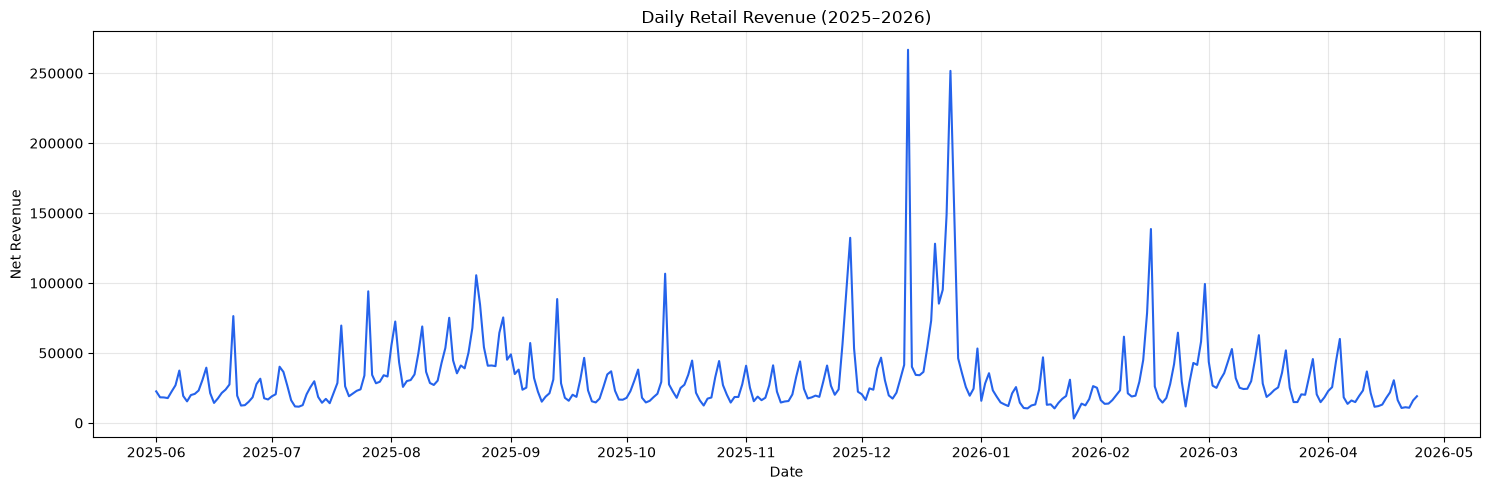

In [23]:
total_daily_sales = daily_sales.groupby("Date")["Sales"].sum()

plt.figure(figsize=(15, 5))

plt.plot(
    total_daily_sales.index,
    total_daily_sales.values,
    color="#2563EB"
)

plt.title("Daily Retail Revenue (2025–2026)")
plt.xlabel("Date")
plt.ylabel("Net Revenue")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Sales Pattern Analysis

Investigate missing dates, weekly sales patterns,
seasonal trends and unusually high sales periods
to identify useful forecasting features.

In [24]:
all_dates = pd.date_range(
    start=daily_sales["Date"].min(),
    end=daily_sales["Date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(
    daily_sales["Date"].unique()
)

print("Completely missing dates:")
print(missing_dates)

Completely missing dates:
DatetimeIndex(['2025-11-27', '2025-12-25'], dtype='datetime64[us]', freq=None)


In [25]:
store_coverage = daily_sales.groupby("Store").agg(
    RecordedDays=("Date", "nunique")
)

store_coverage["MissingDays"] = (
    total_days - store_coverage["RecordedDays"]
)

store_coverage["CoveragePercent"] = (
    store_coverage["RecordedDays"] / total_days * 100
)

store_coverage.sort_values(
    "MissingDays", ascending=False
).head(10)

,RecordedDays,MissingDays,CoveragePercent
Store,,,
STR-1369,297,31,90.548780
STR-1234,302,26,92.073171
STR-1344,302,26,92.073171
STR-1353,303,25,92.378049
STR-1308,305,23,92.987805
STR-1350,309,19,94.207317
STR-1105,309,19,94.207317
STR-1149,312,16,95.121951
STR-1305,314,14,95.731707


DayOfWeek
Monday        558.21
Tuesday       577.64
Wednesday     727.65
Thursday      652.98
Friday        972.15
Saturday     1543.13
Sunday        722.99
Name: Sales, dtype: float64


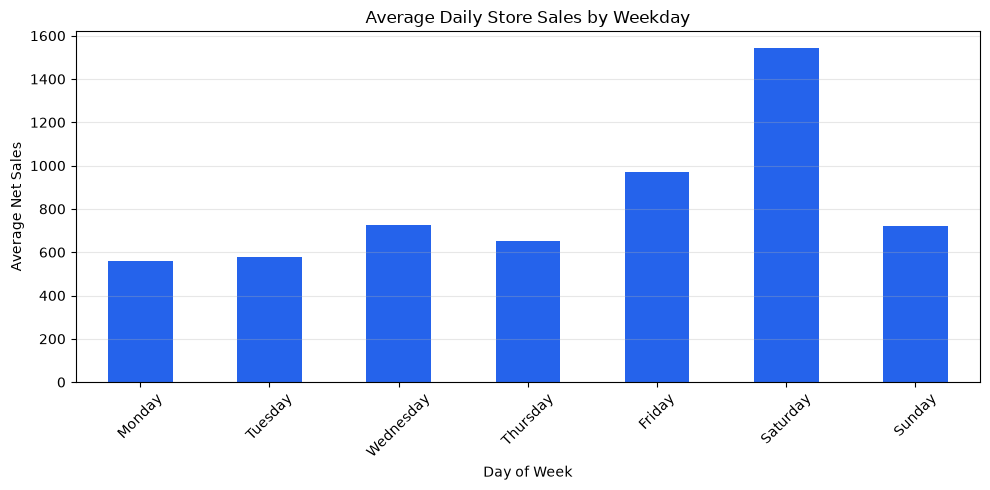

In [26]:
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = daily_sales.groupby(
    "DayOfWeek"
)["Sales"].mean().reindex(weekday_order)

print(weekday_sales.round(2))

weekday_sales.plot(
    kind="bar",
    figsize=(10, 5),
    color="#2563EB"
)

plt.title("Average Daily Store Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Net Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
top_sales_days = total_daily_sales.nlargest(15)

top_sales_days.to_frame(
    name="Total Revenue"
)

,Total Revenue
Date,
2025-12-13,266743.30
2025-12-24,251655.33
2025-12-23,148789.25
2026-02-14,138623.12
2025-11-28,132336.28
2025-12-20,128113.86
2025-10-11,106669.45
2025-08-23,105575.83
2026-02-28,99334.84


## 5. Feature Engineering

Create calendar-based and historical sales features
to improve forecasting performance while preventing
data leakage.

In [28]:
forecast_df = daily_sales.copy()

forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["Day"] = forecast_df["Date"].dt.day
forecast_df["Quarter"] = forecast_df["Date"].dt.quarter

forecast_df["IsWeekend"] = (
    forecast_df["DayOfWeek"] >= 5
).astype(int)

forecast_df[[
    "Date",
    "Store",
    "Sales",
    "DayOfWeek",
    "Month",
    "Day",
    "Quarter",
    "IsWeekend"
]].head(10)

,Date,Store,Sales,DayOfWeek,Month,Day,Quarter,IsWeekend
0,2025-06-01,STR-1006,1145.18,6,6,1,2,1
1,2025-06-01,STR-1010,610.95,6,6,1,2,1
2,2025-06-01,STR-1026,76.50,6,6,1,2,1
3,2025-06-01,STR-1038,634.99,6,6,1,2,1
4,2025-06-01,STR-1044,809.99,6,6,1,2,1
5,2025-06-01,STR-1074,160.00,6,6,1,2,1
6,2025-06-01,STR-1075,1149.94,6,6,1,2,1
7,2025-06-01,STR-1080,1320.00,6,6,1,2,1
8,2025-06-01,STR-1082,554.98,6,6,1,2,1
9,2025-06-01,STR-1085,649.99,6,6,1,2,1


In [29]:
forecast_df["IsChristmasSeason"] = (
    forecast_df["Month"] == 12
).astype(int)

forecast_df["IsChristmasEve"] = (
    (forecast_df["Month"] == 12) &
    (forecast_df["Day"] == 24)
).astype(int)

forecast_df["IsValentinesDay"] = (
    (forecast_df["Month"] == 2) &
    (forecast_df["Day"] == 14)
).astype(int)

forecast_df["IsBlackFriday"] = (
    (forecast_df["Month"] == 11) &
    (forecast_df["DayOfWeek"] == 4) &
    (forecast_df["Day"].between(23, 29))
).astype(int)

In [30]:
forecast_df["IsChristmasSeason"] = (
    forecast_df["Month"] == 12
).astype(int)

forecast_df["IsChristmasEve"] = (
    (forecast_df["Month"] == 12) &
    (forecast_df["Day"] == 24)
).astype(int)

forecast_df["IsValentinesDay"] = (
    (forecast_df["Month"] == 2) &
    (forecast_df["Day"] == 14)
).astype(int)

forecast_df["IsBlackFriday"] = (
    (forecast_df["Month"] == 11) &
    (forecast_df["DayOfWeek"] == 4) &
    (forecast_df["Day"].between(23, 29))
).astype(int)

In [31]:
event_features = [
    "IsChristmasSeason",
    "IsChristmasEve",
    "IsValentinesDay",
    "IsBlackFriday"
]

print(forecast_df[event_features].sum())

forecast_df[
    forecast_df["IsBlackFriday"] == 1
][["Date", "Store", "Sales", "IsBlackFriday"]].head()

IsChristmasSeason    1192
IsChristmasEve         40
IsValentinesDay        40
IsBlackFriday          40
dtype: int64


,Date,Store,Sales,IsBlackFriday
7013,2025-11-28,STR-1006,4250.40,1
7014,2025-11-28,STR-1010,3631.86,1
7015,2025-11-28,STR-1026,2577.29,1
7016,2025-11-28,STR-1038,3025.40,1
7017,2025-11-28,STR-1044,2869.96,1


### Historical Sales Features

Calculate historical store-level and weekday-level
sales averages using only previous observations
to prevent data leakage.

In [32]:
forecast_df = forecast_df.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

forecast_df["PastStoreAvg"] = (
    forecast_df.groupby("Store")["Sales"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

In [33]:
forecast_df["PastStoreWeekdayAvg"] = (
    forecast_df.groupby(
        ["Store", "DayOfWeek"]
    )["Sales"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

In [34]:
forecast_df[[
    "Date",
    "Store",
    "Sales",
    "DayOfWeek",
    "PastStoreAvg",
    "PastStoreWeekdayAvg"
]].head(20)

,Date,Store,Sales,DayOfWeek,PastStoreAvg,PastStoreWeekdayAvg
0,2025-06-01,STR-1006,1145.18,6,NaN,NaN
1,2025-06-02,STR-1006,779.97,0,1145.180000,NaN
2,2025-06-03,STR-1006,1489.99,1,962.575000,NaN
3,2025-06-04,STR-1006,1278.68,2,1138.380000,NaN
4,2025-06-05,STR-1006,1723.63,3,1173.455000,NaN
5,2025-06-06,STR-1006,1431.41,4,1283.490000,NaN
6,2025-06-07,STR-1006,2327.95,5,1308.143333,NaN
7,2025-06-08,STR-1006,600.97,6,1453.830000,1145.180
8,2025-06-09,STR-1006,2065.90,0,1347.222500,779.970
9,2025-06-10,STR-1006,1413.87,1,1427.075556,1489.990


In [35]:
forecast_df[[
    "PastStoreAvg",
    "PastStoreWeekdayAvg"
]].isnull().sum()

PastStoreAvg            40
PastStoreWeekdayAvg    280
dtype: int64

In [36]:
PastStoreAvg = (1145.18 + 779.97) / 2

In [37]:
PastStoreWeekdayAvg = (1145.18 + 600.97) / 2

### Prepare the Forecasting Dataset

Remove observations without sufficient historical
sales information and prepare the dataset for
chronological training, validation and testing.

In [38]:
model_df = forecast_df.dropna(
    subset=[
        "PastStoreAvg",
        "PastStoreWeekdayAvg"
    ]
).copy()

print("Original dataset:", forecast_df.shape)
print("Modeling dataset:", model_df.shape)

print("Removed records:",
      len(forecast_df) - len(model_df))

Original dataset: (12706, 19)
Modeling dataset: (12426, 19)
Removed records: 280


In [39]:
print("Remaining records:", len(model_df))

print("\nMissing historical values:")

print(model_df[[
    "PastStoreAvg",
    "PastStoreWeekdayAvg"
]].isnull().sum())

Remaining records: 12426

Missing historical values:
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64


### Chronological Dataset Split

Divide the dataset into training, validation and
testing periods based on dates to simulate
real-world forecasting and prevent data leakage.

In [40]:
train_df = model_df[
    model_df["Date"] < "2026-01-01"
].copy()

val_df = model_df[
    (model_df["Date"] >= "2026-01-01") &
    (model_df["Date"] < "2026-03-01")
].copy()

test_df = model_df[
    model_df["Date"] >= "2026-03-01"
].copy()

print("Training dataset:", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (8045, 19)
Validation dataset: (2231, 19)
Testing dataset: (2150, 19)


In [41]:
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")
    print("Start date:", df["Date"].min())
    print("End date:", df["Date"].max())
    print("Records:", len(df))
    print("Stores:", df["Store"].nunique())


Training:
Start date: 2025-06-08 00:00:00
End date: 2025-12-31 00:00:00
Records: 8045
Stores: 40

Validation:
Start date: 2026-01-01 00:00:00
End date: 2026-02-28 00:00:00
Records: 2231
Stores: 40

Testing:
Start date: 2026-03-01 00:00:00
End date: 2026-04-24 00:00:00
Records: 2150
Stores: 40


In [42]:
print("No training-validation overlap:",
      train_df["Date"].max() < val_df["Date"].min())

print("No validation-testing overlap:",
      val_df["Date"].max() < test_df["Date"].min())

print("All records preserved:",
      len(train_df) + len(val_df) + len(test_df)
      == len(model_df))

No training-validation overlap: True
No validation-testing overlap: True
All records preserved: True


### Leakage-Safe Historical Features

Recalculate historical sales averages for validation
and testing using only observations available before
the beginning of each forecast period.

In [43]:
def apply_historical_features(target_df, history_df):
    result = target_df.copy()

    store_avg = history_df.groupby("Store")["Sales"].mean()

    weekday_avg = history_df.groupby(
        ["Store", "DayOfWeek"]
    )["Sales"].mean()

    result["PastStoreAvg"] = result["Store"].map(store_avg)

    result["PastStoreWeekdayAvg"] = [
        weekday_avg.get((store, weekday), np.nan)
        for store, weekday in zip(
            result["Store"],
            result["DayOfWeek"]
        )
    ]

    return result

In [44]:
val_history = forecast_df[
    forecast_df["Date"] < "2026-01-01"
]

test_history = forecast_df[
    forecast_df["Date"] < "2026-03-01"
]

val_df = apply_historical_features(
    val_df, val_history
)

test_df = apply_historical_features(
    test_df, test_history
)

In [45]:
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")

    print(df[
        ["PastStoreAvg", "PastStoreWeekdayAvg"]
    ].isnull().sum())


Training:
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64

Validation:
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64

Testing:
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64


In [46]:
test_df[[
    "Date",
    "Store",
    "Sales",
    "DayOfWeek",
    "PastStoreAvg",
    "PastStoreWeekdayAvg"
]].head(10)

,Date,Store,Sales,DayOfWeek,PastStoreAvg,PastStoreWeekdayAvg
268,2026-03-01,STR-1006,2912.96,6,1552.042463,1408.532105
269,2026-03-02,STR-1006,1825.00,0,1552.042463,1042.285676
270,2026-03-03,STR-1006,1200.00,1,1552.042463,1089.425641
271,2026-03-04,STR-1006,2071.85,2,1552.042463,1298.645128
272,2026-03-05,STR-1006,1516.88,3,1552.042463,1550.319730
273,2026-03-06,STR-1006,2292.09,4,1552.042463,2004.484872
274,2026-03-07,STR-1006,1323.94,5,1552.042463,2440.694615
275,2026-03-08,STR-1006,2348.10,6,1552.042463,1408.532105
276,2026-03-09,STR-1006,1367.94,0,1552.042463,1042.285676
277,2026-03-10,STR-1006,1754.88,1,1552.042463,1089.425641


### Feature and Target Selection

Select relevant calendar, special event and historical
sales features for the forecasting model.

Encode store identifiers and prepare training,
validation and testing inputs and target variables.

In [47]:
features = [
    "Store",
    "DayOfWeek",
    "Month",
    "Day",
    "Quarter",
    "IsWeekend",
    "IsChristmasSeason",
    "IsChristmasEve",
    "IsValentinesDay",
    "IsBlackFriday",
    "PastStoreAvg",
    "PastStoreWeekdayAvg"
]

target = "Sales"

print("Number of input features:", len(features))
print("Target variable:", target)

Number of input features: 12
Target variable: Sales


In [48]:
X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_val = val_df[features].copy()
y_val = val_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

In [49]:
X_train = pd.get_dummies(
    X_train, columns=["Store"], dtype=int
)

X_val = pd.get_dummies(
    X_val, columns=["Store"], dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=["Store"], dtype=int
)

X_val = X_val.reindex(
    columns=X_train.columns, fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns, fill_value=0
)

In [50]:
print("Training inputs:", X_train.shape)
print("Training target:", y_train.shape)

print("\nValidation inputs:", X_val.shape)
print("Validation target:", y_val.shape)

print("\nTesting inputs:", X_test.shape)
print("Testing target:", y_test.shape)

Training inputs: (8045, 51)
Training target: (8045,)

Validation inputs: (2231, 51)
Validation target: (2231,)

Testing inputs: (2150, 51)
Testing target: (2150,)


In [51]:
print("Validation features match:",
      X_train.columns.equals(X_val.columns))

print("Testing features match:",
      X_train.columns.equals(X_test.columns))

print("\nTraining missing values:",
      X_train.isnull().sum().sum())

print("Validation missing values:",
      X_val.isnull().sum().sum())

print("Testing missing values:",
      X_test.isnull().sum().sum())

Validation features match: True
Testing features match: True

Training missing values: 0
Validation missing values: 0
Testing missing values: 0


### Baseline Forecasting Model

Implement a non-AI forecasting baseline using
historical store-specific weekday averages.

Evaluate the baseline using Mean Absolute Error
(MAE) and Root Mean Squared Error (RMSE) to
establish a benchmark for machine learning models.

In [52]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [53]:
baseline_val_predictions = X_val[
    "PastStoreWeekdayAvg"
].to_numpy()

baseline_test_predictions = X_test[
    "PastStoreWeekdayAvg"
].to_numpy()

print("Validation predictions:",
      len(baseline_val_predictions))

print("Testing predictions:",
      len(baseline_test_predictions))

Validation predictions: 2231
Testing predictions: 2150


In [54]:
baseline_val_mae = mean_absolute_error(
    y_val, baseline_val_predictions
)

baseline_val_rmse = np.sqrt(
    mean_squared_error(
        y_val, baseline_val_predictions
    )
)

print(f"Baseline validation MAE: {baseline_val_mae:.2f}")
print(f"Baseline validation RMSE: {baseline_val_rmse:.2f}")

Baseline validation MAE: 479.69
Baseline validation RMSE: 647.07


In [57]:
baseline_comparison.head(10).round({
    "Actual Sales": 2,
    "Predicted Sales": 2,
    "Absolute Error": 2
})

,Date,Store,Actual Sales,Predicted Sales,Absolute Error
0,2026-01-01,STR-1006,489.94,1729.36,1239.42
1,2026-01-02,STR-1006,1729.74,2142.39,412.65
2,2026-01-03,STR-1006,1325.44,2547.32,1221.88
3,2026-01-04,STR-1006,1536.94,1499.86,37.08
4,2026-01-05,STR-1006,858.81,1089.29,230.48
5,2026-01-06,STR-1006,613.19,1216.70,603.51
6,2026-01-07,STR-1006,399.96,1416.42,1016.46
7,2026-01-08,STR-1006,922.98,1729.36,806.38
8,2026-01-09,STR-1006,654.94,2142.39,1487.45
9,2026-01-10,STR-1006,1309.91,2547.32,1237.41


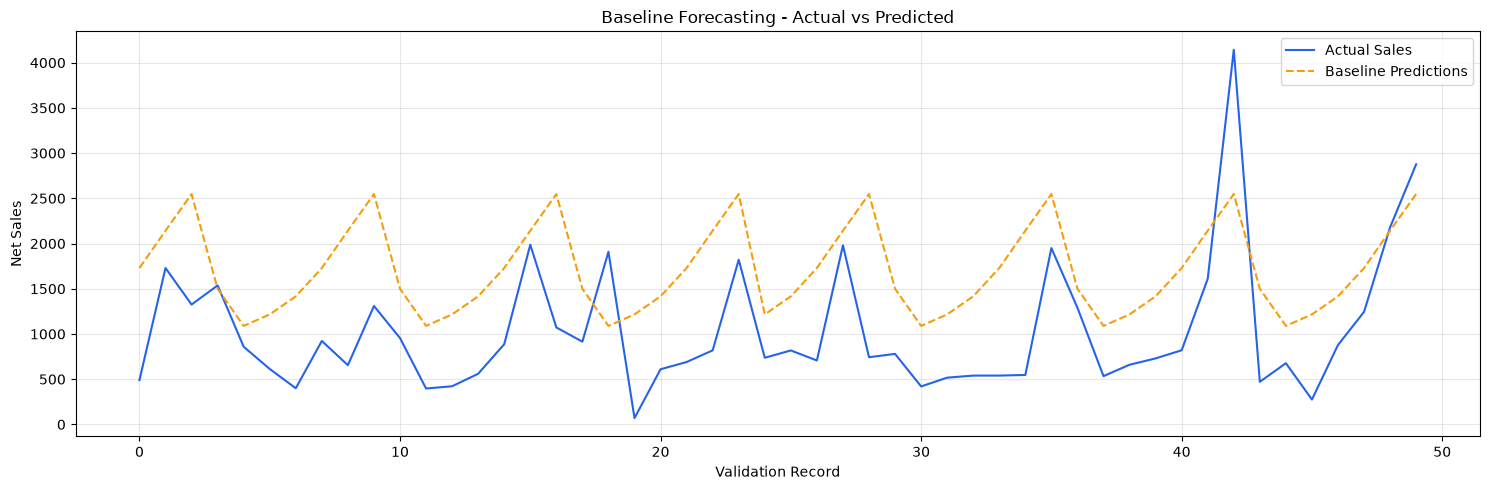

In [56]:
plt.figure(figsize=(15, 5))

plt.plot(
    baseline_comparison["Actual Sales"].head(50),
    label="Actual Sales",
    color="#2563EB"
)

plt.plot(
    baseline_comparison["Predicted Sales"].head(50),
    label="Baseline Predictions",
    color="#F59E0B",
    linestyle="--"
)

plt.title("Baseline Forecasting - Actual vs Predicted")
plt.xlabel("Validation Record")
plt.ylabel("Net Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.15 Decision Tree Model Training

Train a Decision Tree regression model using calendar,
seasonal, event-related and historical sales features.

Evaluate its forecasting performance on the validation
dataset and compare it against the historical baseline
using MAE and RMSE.

In [58]:
from sklearn.tree import DecisionTreeRegressor

decision_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [59]:
dt_val_predictions = decision_tree.predict(X_val)

print("Validation predictions:", len(dt_val_predictions))

Validation predictions: 2231


In [60]:
dt_val_mae = mean_absolute_error(
    y_val, dt_val_predictions
)

dt_val_rmse = np.sqrt(
    mean_squared_error(
        y_val, dt_val_predictions
    )
)

print(f"Decision Tree validation MAE: {dt_val_mae:.2f}")
print(f"Decision Tree validation RMSE: {dt_val_rmse:.2f}")

Decision Tree validation MAE: 492.43
Decision Tree validation RMSE: 687.91


In [61]:
validation_results = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Decision Tree"
    ],
    "MAE": [
        baseline_val_mae,
        dt_val_mae
    ],
    "RMSE": [
        baseline_val_rmse,
        dt_val_rmse
    ]
})

validation_results.round(2)

,Model,MAE,RMSE
0,Historical Baseline,479.69,647.07
1,Decision Tree,492.43,687.91


The Decision Tree model achieved a validation MAE
of 492.43 and an RMSE of 687.91.

Both errors are higher than those of the historical
baseline, indicating that the current Decision Tree
configuration does not improve forecasting performance.

Further experiments with Random Forest will be
conducted to determine whether ensemble learning
can improve prediction accuracy.

### 1.16 Random Forest Model Training

Train a Random Forest regression model using the same
calendar, seasonal, event-related and historical
sales features.

Evaluate its performance on the validation dataset
and compare the results against the historical
baseline and Decision Tree model using MAE and RMSE.

In [62]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [63]:
rf_val_predictions = random_forest.predict(X_val)

print("Validation predictions:",
      len(rf_val_predictions))

Validation predictions: 2231


In [64]:
rf_val_mae = mean_absolute_error(
    y_val, rf_val_predictions
)

rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val, rf_val_predictions
    )
)

print(f"Random Forest validation MAE: {rf_val_mae:.2f}")
print(f"Random Forest validation RMSE: {rf_val_rmse:.2f}")

Random Forest validation MAE: 519.44
Random Forest validation RMSE: 694.62


In [65]:
validation_results = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_val_mae,
        dt_val_mae,
        rf_val_mae
    ],
    "RMSE": [
        baseline_val_rmse,
        dt_val_rmse,
        rf_val_rmse
    ]
})

validation_results.round(2)

,Model,MAE,RMSE
0,Historical Baseline,479.69,647.07
1,Decision Tree,492.43,687.91
2,Random Forest,519.44,694.62


### 1.17 Model Optimization and Feature Improvement

Investigate the performance of the machine learning
models and identify potential reasons for their
higher forecasting errors compared to the baseline.

#### 1.17.1 Training vs Validation Performance

Compare training and validation errors to identify
potential overfitting and evaluate the ability of
the models to generalize to unseen data.

In [66]:
dt_train_predictions = decision_tree.predict(X_train)

rf_train_predictions = random_forest.predict(X_train)

print("Decision Tree predictions:", len(dt_train_predictions))
print("Random Forest predictions:", len(rf_train_predictions))

Decision Tree predictions: 8045
Random Forest predictions: 8045


In [67]:
dt_train_mae = mean_absolute_error(
    y_train, dt_train_predictions
)

dt_train_rmse = np.sqrt(
    mean_squared_error(y_train, dt_train_predictions)
)

rf_train_mae = mean_absolute_error(
    y_train, rf_train_predictions
)

rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_predictions)
)

In [68]:
overfitting_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Training MAE": [
        dt_train_mae,
        rf_train_mae
    ],
    "Validation MAE": [
        dt_val_mae,
        rf_val_mae
    ],
    "Training RMSE": [
        dt_train_rmse,
        rf_train_rmse
    ],
    "Validation RMSE": [
        dt_val_rmse,
        rf_val_rmse
    ]
})

overfitting_results.round(2)

,Model,Training MAE,Validation MAE,Training RMSE,Validation RMSE
0,Decision Tree,355.72,492.43,529.34,687.91
1,Random Forest,275.93,519.44,431.58,694.62


#### 1.17.2 Random Forest Hyperparameter Optimization

Evaluate different Random Forest hyperparameter
configurations to reduce overfitting and improve
forecasting performance.

Select the best configuration based on validation
MAE while keeping the test dataset independent
for final evaluation.

In [71]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [5, 10, 20],
    "max_features": [0.5, 1.0]
}

parameter_combinations = list(ParameterGrid(param_grid))

print("Total configurations:", len(parameter_combinations))

Total configurations: 36


In [72]:
optimization_results = []

for params in parameter_combinations:

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    optimization_results.append({
        **params,
        "MAE": mae,
        "RMSE": rmse
    })

print("Hyperparameter optimization completed.")

Hyperparameter optimization completed.


In [73]:
optimization_df = pd.DataFrame(optimization_results)

optimization_df = optimization_df.sort_values(
    "MAE"
).reset_index(drop=True)

optimization_df.head(10).round(2)

,max_depth,max_features,min_samples_leaf,n_estimators,MAE,RMSE
0,5,0.5,5,100,503.61,657.19
1,5,0.5,5,200,504.72,658.80
2,5,0.5,10,200,506.58,659.97
3,5,0.5,10,100,507.24,659.92
4,10,1.0,10,200,507.76,679.71
5,5,1.0,5,100,507.80,665.75
6,10,1.0,10,100,509.64,680.49
7,5,1.0,5,200,509.77,666.88
8,10,0.5,10,100,510.29,672.32
9,15,0.5,20,100,510.36,669.57


In [74]:
best_config = optimization_df.iloc[0]

print("Best configuration:")
print(best_config)

print("\nHistorical Baseline MAE:", round(baseline_val_mae, 2))
print("Original Random Forest MAE:", round(rf_val_mae, 2))
print("Optimized Random Forest MAE:", round(best_config["MAE"], 2))

Best configuration:
max_depth             5.000000
max_features          0.500000
min_samples_leaf      5.000000
n_estimators        100.000000
MAE                 503.613159
RMSE                657.187225
Name: 0, dtype: float64

Historical Baseline MAE: 479.69
Original Random Forest MAE: 519.44
Optimized Random Forest MAE: 503.61


**Hyperparameter Optimization Findings**

The optimized Random Forest achieved a validation
MAE of 503.61 and RMSE of 657.19.

Compared to the original Random Forest, this
represents a 3.05% reduction in MAE and a 5.39%
reduction in RMSE.

However, the historical baseline continues to
outperform the machine learning models.

These findings suggest that further investigation
of historical sales patterns, seasonality and
input features is necessary to improve forecasting
performance.

#### 1.17.3 Feature Importance Analysis

Analyze the importance of input features in the
optimized Random Forest model to identify the
most influential factors in sales forecasting.

Evaluate the contribution of historical sales,
calendar, seasonal and event-related features
to identify potential improvements.

In [75]:
optimized_rf = RandomForestRegressor(
    n_estimators=int(best_config["n_estimators"]),
    max_depth=int(best_config["max_depth"]),
    min_samples_leaf=int(best_config["min_samples_leaf"]),
    max_features=float(best_config["max_features"]),
    random_state=42,
    n_jobs=-1
)

optimized_rf.fit(X_train, y_train)

print("Optimized Random Forest training completed.")

Optimized Random Forest training completed.


In [76]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": optimized_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance.head(15).round(4)

,Feature,Importance
0,PastStoreWeekdayAvg,0.3014
1,IsChristmasEve,0.2943
2,Day,0.1073
3,Month,0.0726
4,PastStoreAvg,0.0572
5,IsChristmasSeason,0.0510
6,IsBlackFriday,0.0484
7,DayOfWeek,0.0433
8,IsWeekend,0.0147
9,Quarter,0.0027


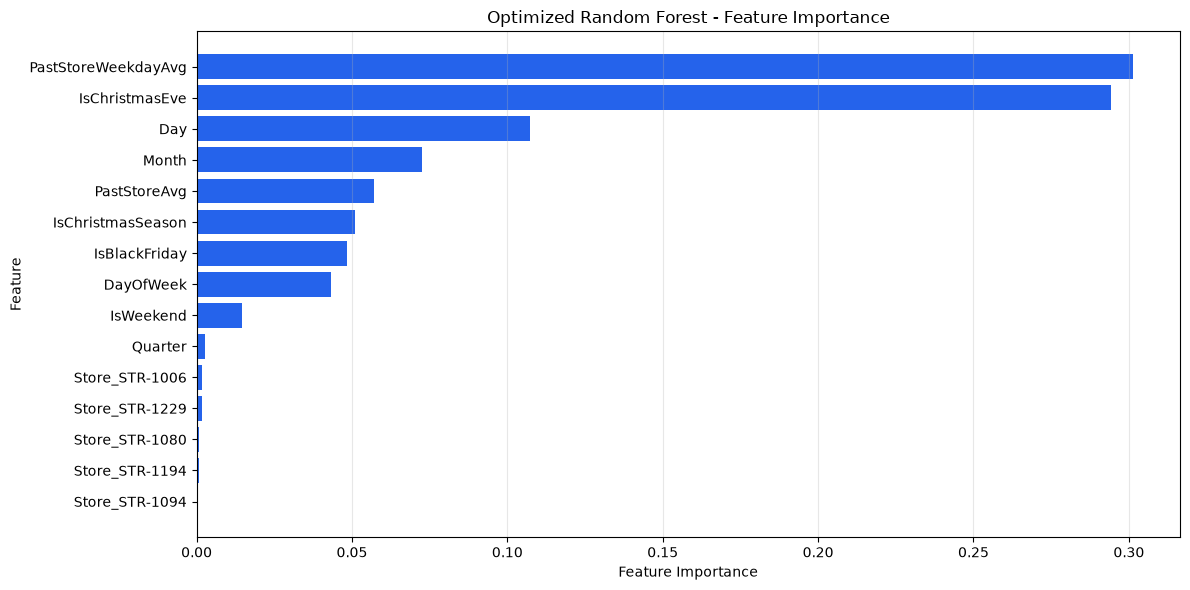

In [77]:
top_features = feature_importance.head(15)

plt.figure(figsize=(12, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="#2563EB"
)

plt.gca().invert_yaxis()

plt.title("Optimized Random Forest - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**Feature Importance Findings**

The feature importance analysis identified
PastStoreWeekdayAvg as the most influential
feature, accounting for 30.14% of the total
feature importance.

Christmas Eve also demonstrated significant
importance at 29.43%, indicating that the model
strongly relies on this seasonal event.

Individual store identifiers showed relatively
low importance.

Further investigation is necessary to determine
whether recent historical sales patterns can
improve forecasting performance.

#### 1.17.4 Advanced Historical Feature Engineering

Introduce lag-based and rolling historical sales
features to capture recent sales behavior and
short-term business trends.

Ensure that historical features use only sales
information available before the forecast period
to prevent data leakage.

Evaluate whether these additional features
improve forecasting performance.

In [78]:
daily_check = train_df[
    ["Store", "Date"]
].copy()

daily_check["Date"] = pd.to_datetime(
    daily_check["Date"]
)

daily_check = daily_check.sort_values(
    ["Store", "Date"]
)

daily_check["DayGap"] = (
    daily_check.groupby("Store")["Date"]
    .diff()
    .dt.days
)

print("Duplicate store-date records:",
      daily_check.duplicated(
          ["Store", "Date"]
      ).sum())

print("\nDay gap distribution:")
print(
    daily_check["DayGap"]
    .value_counts()
    .sort_index()
)

Duplicate store-date records: 0

Day gap distribution:
DayGap
1.0    7784
2.0     211
3.0       7
4.0       2
5.0       1
Name: count, dtype: int64


**Daily Data Continuity Findings**

No duplicate store-date records were detected.

Approximately 97.24% of consecutive records
are separated by exactly one day.

However, some gaps of two to five days exist
in the training dataset.

Therefore, advanced historical features must
be calculated using calendar-based dates
rather than row-based shifting to ensure
accurate historical alignment.

In [79]:
advanced_features = [
    "SalesLag7",
    "SalesLag14",
    "RollingMean7",
    "RollingMean30",
    "RecentSalesTrend"
]

def add_advanced_features(target_df, history_df):

    result = target_df.copy()
    history = history_df.copy()

    result["Date"] = pd.to_datetime(result["Date"])
    history["Date"] = pd.to_datetime(history["Date"])

    for feature in advanced_features:
        result[feature] = np.nan

    for store, group in result.groupby("Store"):

        store_history = history[
            history["Store"] == store
        ].set_index("Date")["Sales"].sort_index()

        for idx, row in group.iterrows():

            date = row["Date"]

            past = store_history[
                store_history.index < date
            ]

            result.loc[idx, "SalesLag7"] = past.get(
                date - pd.Timedelta(days=7), np.nan
            )

            result.loc[idx, "SalesLag14"] = past.get(
                date - pd.Timedelta(days=14), np.nan
            )

            mean7 = past[
                past.index >= date - pd.Timedelta(days=7)
            ].mean()

            mean30 = past[
                past.index >= date - pd.Timedelta(days=30)
            ].mean()

            result.loc[idx, "RollingMean7"] = mean7
            result.loc[idx, "RollingMean30"] = mean30

            if pd.notna(mean30) and mean30 > 0:
                result.loc[idx, "RecentSalesTrend"] = (
                    mean7 / mean30
                )

    return result

In [82]:
train_advanced = add_advanced_features(
    train_df,
    train_df
)

print("Advanced training features created.")

train_advanced[
    ["Store", "Date", "Sales"] + advanced_features
].head(20).round({
    "Sales": 2,
    **{feature: 2 for feature in advanced_features}
})

Advanced training features created.


,Store,Date,Sales,SalesLag7,SalesLag14,RollingMean7,RollingMean30,RecentSalesTrend
7,STR-1006,2025-06-08,600.97,NaN,NaN,NaN,NaN,NaN
8,STR-1006,2025-06-09,2065.90,NaN,NaN,600.97,600.97,1.00
9,STR-1006,2025-06-10,1413.87,NaN,NaN,1333.44,1333.44,1.00
10,STR-1006,2025-06-11,837.44,NaN,NaN,1360.25,1360.25,1.00
11,STR-1006,2025-06-12,1365.98,NaN,NaN,1229.54,1229.54,1.00
12,STR-1006,2025-06-13,1354.95,NaN,NaN,1256.83,1256.83,1.00
13,STR-1006,2025-06-14,1057.47,NaN,NaN,1273.18,1273.18,1.00
14,STR-1006,2025-06-15,1402.95,600.97,NaN,1242.37,1242.37,1.00
15,STR-1006,2025-06-16,619.99,2065.90,NaN,1356.94,1262.44,1.07
16,STR-1006,2025-06-17,1090.67,1413.87,NaN,1150.38,1191.06,0.97


In [81]:
print("Missing advanced feature values:")

print(
    train_advanced[advanced_features]
    .isnull()
    .sum()
)

Missing advanced feature values:
SalesLag7           451
SalesLag14          723
RollingMean7         40
RollingMean30        40
RecentSalesTrend     40
dtype: int64


#### Handling Missing Advanced Feature Values

Replace missing lag and rolling average values with
available historical sales averages.

Remove records without sufficient historical information
to prevent unreliable feature values and data leakage.

In [83]:
train_advanced_clean = train_advanced.copy()

# Fill missing lag values using historical averages
for feature in ["SalesLag7", "SalesLag14"]:
    train_advanced_clean[feature] = (
        train_advanced_clean[feature]
        .fillna(train_advanced_clean["PastStoreWeekdayAvg"])
        .fillna(train_advanced_clean["PastStoreAvg"])
    )

# Fill missing rolling averages
for feature in ["RollingMean7", "RollingMean30"]:
    train_advanced_clean[feature] = (
        train_advanced_clean[feature]
        .fillna(train_advanced_clean["PastStoreAvg"])
    )

# Remove remaining missing advanced feature values
train_advanced_clean = train_advanced_clean.dropna(
    subset=advanced_features
).copy()

In [84]:
print("Original training records:", len(train_advanced))
print("Cleaned training records:", len(train_advanced_clean))

print(
    "Removed records:",
    len(train_advanced) - len(train_advanced_clean)
)

print("\nRemaining missing values:")

print(
    train_advanced_clean[advanced_features]
    .isnull()
    .sum()
)

Original training records: 8045
Cleaned training records: 8005
Removed records: 40

Remaining missing values:
SalesLag7           0
SalesLag14          0
RollingMean7        0
RollingMean30       0
RecentSalesTrend    0
dtype: int64


#### Advanced Validation Feature Engineering

Generate lag values, rolling sales averages and recent
sales trends for the validation dataset using historical
training data only.

This prevents future sales information from influencing
validation predictions.

In [85]:
historical_sales = (
    train_advanced[["Store", "Date", "Sales"]]
    .sort_values(["Store", "Date"])
    .copy()
)

store_history = {
    store: group.set_index("Date")["Sales"].sort_index()
    for store, group in historical_sales.groupby("Store")
}

print("Stores with historical data:", len(store_history))
print("Historical records:", len(historical_sales))
print("Last historical date:", historical_sales["Date"].max())

Stores with historical data: 40
Historical records: 8045
Last historical date: 2025-12-31 00:00:00


In [86]:
print("Validation records:", len(X_val))
print("Historical stores:", len(store_history))

print("\nExample store history:")
print(store_history["STR-1006"].tail(10))

Validation records: 2231
Historical stores: 40

Example store history:
Date
2025-12-21    2624.91
2025-12-22    3193.41
2025-12-23    5136.11
2025-12-24    9566.40
2025-12-26    1877.96
2025-12-27    2368.94
2025-12-28     735.47
2025-12-29     274.98
2025-12-30     859.95
2025-12-31    3700.63
Name: Sales, dtype: float64


In [87]:
def calculate_validation_features(row):
    store = row["Store"]
    date = pd.Timestamp(row["Date"])

    history = store_history[store]
    history = history[history.index < date]

    fallback = row["PastStoreWeekdayAvg"]

    lag7 = history.get(
        date - pd.Timedelta(days=7), fallback
    )

    lag14 = history.get(
        date - pd.Timedelta(days=14), fallback
    )

    rolling7 = history[
        history.index >= date - pd.Timedelta(days=7)
    ].mean()

    rolling30 = history[
        history.index >= date - pd.Timedelta(days=30)
    ].mean()

    if pd.isna(rolling7):
        rolling7 = fallback

    if pd.isna(rolling30):
        rolling30 = row["PastStoreAvg"]

    trend = rolling7 / rolling30 if rolling30 > 0 else 1.0

    return pd.Series({
        "SalesLag7": lag7,
        "SalesLag14": lag14,
        "RollingMean7": rolling7,
        "RollingMean30": rolling30,
        "RecentSalesTrend": trend
    })

In [88]:
val_advanced = val_df.copy()

val_advanced[advanced_features] = val_advanced.apply(
    calculate_validation_features,
    axis=1
)

print("Advanced validation features created.")

val_advanced[
    ["Store", "Date", "Sales"] + advanced_features
].head(20)

Advanced validation features created.


,Store,Date,Sales,SalesLag7,SalesLag14,RollingMean7,RollingMean30,RecentSalesTrend
212,STR-1006,2026-01-01,489.94,1729.363571,3070.950000,1636.321667,2397.570345,0.682492
213,STR-1006,2026-01-02,1729.74,1877.960000,3086.220000,1636.321667,2463.824286,0.664139
214,STR-1006,2026-01-03,1325.44,2368.940000,4332.900000,1587.994000,2518.078148,0.630637
215,STR-1006,2026-01-04,1536.94,735.470000,2624.910000,1392.757500,2586.177308,0.538539
216,STR-1006,2026-01-05,858.81,274.980000,3193.410000,1611.853333,2562.449600,0.629028
217,STR-1006,2026-01-06,613.19,859.950000,5136.110000,2280.290000,2546.138750,0.895587
218,STR-1006,2026-01-07,399.96,3700.630000,9566.400000,3700.630000,2616.971304,1.414089
219,STR-1006,2026-01-08,922.98,1729.363571,1729.363571,1729.363571,2702.100455,0.640007
220,STR-1006,2026-01-09,654.94,2142.388000,1877.960000,2142.388000,2812.962381,0.761613
221,STR-1006,2026-01-10,1309.91,2547.319667,2368.940000,2547.319667,2921.862000,0.871814


In [89]:
print("Validation records:", len(val_advanced))

print("\nMissing advanced feature values:")

print(
    val_advanced[advanced_features]
    .isnull()
    .sum()
)

Validation records: 2231

Missing advanced feature values:
SalesLag7           0
SalesLag14          0
RollingMean7        0
RollingMean30       0
RecentSalesTrend    0
dtype: int64


#### Advanced Feature Matrix Preparation

Combine the existing calendar, seasonal, event-related
and historical sales features with the newly created
lag values, rolling averages and recent sales trends.

Prepare consistent training and validation feature
matrices for the advanced Random Forest model.

In [90]:
X_train_advanced = X_train.loc[
    train_advanced_clean.index
].copy()

X_val_advanced = X_val.copy()

for feature in advanced_features:
    X_train_advanced[feature] = train_advanced_clean[feature]
    X_val_advanced[feature] = val_advanced[feature]

y_train_advanced = train_advanced_clean["Sales"].copy()
y_val_advanced = y_val.copy()

print("Advanced feature matrices created.")

Advanced feature matrices created.


In [91]:
print("Original training shape:", X_train.shape)
print("Advanced training shape:", X_train_advanced.shape)

print("\nOriginal validation shape:", X_val.shape)
print("Advanced validation shape:", X_val_advanced.shape)

print("\nFeature columns match:",
      X_train_advanced.columns.equals(
          X_val_advanced.columns
      ))

print("Training indices match:",
      X_train_advanced.index.equals(y_train_advanced.index))

print("Validation indices match:",
      X_val_advanced.index.equals(y_val_advanced.index))

print("\nMissing training values:",
      X_train_advanced.isnull().sum().sum())

print("Missing validation values:",
      X_val_advanced.isnull().sum().sum())

Original training shape: (8045, 51)
Advanced training shape: (8005, 56)

Original validation shape: (2231, 51)
Advanced validation shape: (2231, 56)

Feature columns match: True
Training indices match: True
Validation indices match: True

Missing training values: 0
Missing validation values: 0


#### Advanced Random Forest Model Training

Train a Random Forest regression model using the
extended feature set, including sales lag values,
rolling averages and recent sales trends.

Evaluate whether advanced historical features improve
forecasting performance compared to previous models
and the historical baseline.

In [92]:
advanced_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    max_features=0.5,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

advanced_rf.fit(X_train_advanced, y_train_advanced)

print("Advanced Random Forest training completed.")

Advanced Random Forest training completed.


In [93]:
advanced_rf_val_predictions = advanced_rf.predict(
    X_val_advanced
)

print(
    "Validation predictions:",
    len(advanced_rf_val_predictions)
)

Validation predictions: 2231


In [94]:
advanced_rf_val_mae = mean_absolute_error(
    y_val_advanced,
    advanced_rf_val_predictions
)

advanced_rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val_advanced,
        advanced_rf_val_predictions
    )
)

print(f"Advanced Random Forest MAE: {advanced_rf_val_mae:.2f}")
print(f"Advanced Random Forest RMSE: {advanced_rf_val_rmse:.2f}")

Advanced Random Forest MAE: 489.22
Advanced Random Forest RMSE: 660.04


#### Fair Model Comparison

Retrain the optimized Random Forest using the same
training records as the advanced model.

This ensures a fair comparison and helps determine
whether the additional historical sales features
improve prediction performance.

In [95]:
X_train_fair = X_train.loc[X_train_advanced.index].copy()
y_train_fair = y_train_advanced.copy()

print("Fair training shape:", X_train_fair.shape)
print("Advanced training shape:", X_train_advanced.shape)

print(
    "Training indices match:",
    X_train_fair.index.equals(X_train_advanced.index)
)

Fair training shape: (8005, 51)
Advanced training shape: (8005, 56)
Training indices match: True


In [96]:
from sklearn.base import clone

fair_rf = clone(optimized_rf)

fair_rf.fit(X_train_fair, y_train_fair)

print("Fair Random Forest training completed.")

Fair Random Forest training completed.


In [97]:
fair_rf_predictions = fair_rf.predict(X_val)

fair_rf_mae = mean_absolute_error(
    y_val, fair_rf_predictions
)

fair_rf_rmse = np.sqrt(
    mean_squared_error(y_val, fair_rf_predictions)
)

print(f"Fair Random Forest MAE: {fair_rf_mae:.2f}")
print(f"Fair Random Forest RMSE: {fair_rf_rmse:.2f}")

Fair Random Forest MAE: 509.45
Fair Random Forest RMSE: 661.99


### 1.18 Final Advanced Model Optimization

Optimize the Random Forest model using the expanded
feature set, including historical sales patterns,
lag features, rolling averages and recent sales trends.

Compare different hyperparameter configurations
using validation MAE and RMSE to identify the
best-performing advanced model.

In [98]:
from sklearn.model_selection import ParameterGrid

advanced_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [5, 10, 20],
    "max_features": [0.5, 1.0]
}

advanced_configs = list(
    ParameterGrid(advanced_param_grid)
)

print("Configurations to test:", len(advanced_configs))

Configurations to test: 48


In [99]:
advanced_optimization_results = []

for params in advanced_configs:

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_advanced, y_train_advanced)

    predictions = model.predict(X_val_advanced)

    mae = mean_absolute_error(
        y_val_advanced, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_advanced, predictions
        )
    )

    advanced_optimization_results.append({
        **params,
        "MAE": mae,
        "RMSE": rmse
    })

print("Advanced model optimization completed.")

Advanced model optimization completed.


In [100]:
advanced_optimization_df = pd.DataFrame(
    advanced_optimization_results
)

advanced_optimization_df = (
    advanced_optimization_df
    .sort_values("MAE")
    .reset_index(drop=True)
)

advanced_optimization_df.head(10).round(2)

,max_depth,max_features,min_samples_leaf,n_estimators,MAE,RMSE
0,3,1.0,20,200,483.16,658.71
1,3,1.0,5,200,483.63,660.31
2,3,1.0,10,200,483.89,660.35
3,3,1.0,20,100,484.01,659.48
4,3,1.0,5,100,484.35,660.74
5,3,1.0,10,100,484.74,661.01
6,10,0.5,20,100,486.61,676.59
7,7,0.5,20,100,487.62,670.10
8,5,0.5,5,200,488.26,662.05
9,5,0.5,10,200,488.67,664.18


In [101]:
best_advanced_config = advanced_optimization_df.iloc[0]

print("Best advanced configuration:")
print(best_advanced_config)

print("\nHistorical Baseline MAE:",
      round(baseline_val_mae, 2))

print("Previous Advanced RF MAE:",
      round(advanced_rf_val_mae, 2))

print("Optimized Advanced RF MAE:",
      round(best_advanced_config["MAE"], 2))

Best advanced configuration:
max_depth             3.000000
max_features          1.000000
min_samples_leaf     20.000000
n_estimators        200.000000
MAE                 483.160249
RMSE                658.711499
Name: 0, dtype: float64

Historical Baseline MAE: 479.69
Previous Advanced RF MAE: 489.22
Optimized Advanced RF MAE: 483.16


### 1.19 Independent Test Dataset Evaluation

Train the final optimized Advanced Random Forest
using the best hyperparameter configuration.

Evaluate its performance on the independent test
dataset and compare the results against the
historical baseline and previous machine learning
models using MAE and RMSE.

In [103]:
final_advanced_rf = RandomForestRegressor(
    n_estimators=int(best_advanced_config["n_estimators"]),
    max_depth=int(best_advanced_config["max_depth"]),
    min_samples_leaf=int(best_advanced_config["min_samples_leaf"]),
    max_features=float(best_advanced_config["max_features"]),
    random_state=42,
    n_jobs=-1
)

final_advanced_rf.fit(
    X_train_advanced,
    y_train_advanced
)

print("Final Advanced Random Forest training completed.")

Final Advanced Random Forest training completed.


In [105]:
final_val_predictions = final_advanced_rf.predict(
    X_val_advanced
)

final_val_mae = mean_absolute_error(
    y_val_advanced,
    final_val_predictions
)

final_val_rmse = np.sqrt(
    mean_squared_error(
        y_val_advanced,
        final_val_predictions
    )
)

print(f"Final validation MAE: {final_val_mae:.2f}")
print(f"Final validation RMSE: {final_val_rmse:.2f}")

Final validation MAE: 483.16
Final validation RMSE: 658.71


#### 1.19.1 Independent Test Data Preparation

Inspect the independent test dataset and verify
its chronological separation from the training
and validation datasets.

Prepare the historical information required for
feature engineering without using future sales
values.

In [106]:
print("Test dataset shape:", test_df.shape)

print("\nTest dataset columns:")
print(test_df.columns.tolist())

print("\nTest date range:")
print("Start:", test_df["Date"].min())
print("End:", test_df["Date"].max())

print("\nNumber of stores:")
print(test_df["Store"].nunique())

print("\nMissing values:")
print(test_df.isnull().sum())

Test dataset shape: (2150, 19)

Test dataset columns:
['Date', 'Store', 'Sales', 'COGS', 'GrossProfit', 'QuantitySold', 'Transactions', 'ReturnRecords', 'DayOfWeek', 'Month', 'Day', 'Quarter', 'IsWeekend', 'IsChristmasSeason', 'IsChristmasEve', 'IsValentinesDay', 'IsBlackFriday', 'PastStoreAvg', 'PastStoreWeekdayAvg']

Test date range:
Start: 2026-03-01 00:00:00
End: 2026-04-24 00:00:00

Number of stores:
40

Missing values:
Date                   0
Store                  0
Sales                  0
COGS                   0
GrossProfit            0
QuantitySold           0
Transactions           0
ReturnRecords          0
DayOfWeek              0
Month                  0
Day                    0
Quarter                0
IsWeekend              0
IsChristmasSeason      0
IsChristmasEve         0
IsValentinesDay        0
IsBlackFriday          0
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64


In [107]:
test_df[["Store", "Date", "Sales"]].head(10)

,Store,Date,Sales
268,STR-1006,2026-03-01,2912.96
269,STR-1006,2026-03-02,1825.00
270,STR-1006,2026-03-03,1200.00
271,STR-1006,2026-03-04,2071.85
272,STR-1006,2026-03-05,1516.88
273,STR-1006,2026-03-06,2292.09
274,STR-1006,2026-03-07,1323.94
275,STR-1006,2026-03-08,2348.10
276,STR-1006,2026-03-09,1367.94
277,STR-1006,2026-03-10,1754.88


In [108]:
print("Total missing values:",
      test_df.isnull().sum().sum())

print("Duplicate store-date records:",
      test_df.duplicated(["Store", "Date"]).sum())

print("Last validation date:",
      val_advanced["Date"].max())

print("Chronological separation:",
      val_advanced["Date"].max() < test_df["Date"].min())

Total missing values: 0
Duplicate store-date records: 0
Last validation date: 2026-02-28 00:00:00
Chronological separation: True


#### Advanced Test Feature Engineering

Generate advanced historical sales features for the
test dataset using training and validation data
available before the test period.

This ensures that future sales information does not
influence the final model evaluation.

In [109]:
test_historical_sales = pd.concat(
    [
        train_advanced[["Store", "Date", "Sales"]],
        val_advanced[["Store", "Date", "Sales"]]
    ],
    ignore_index=True
)

test_historical_sales = test_historical_sales.sort_values(
    ["Store", "Date"]
)

test_store_history = {
    store: group.set_index("Date")["Sales"].sort_index()
    for store, group in test_historical_sales.groupby("Store")
}

In [110]:
print("Historical records:", len(test_historical_sales))

print("Historical stores:", len(test_store_history))

print("Last historical date:",
      test_historical_sales["Date"].max())

print("No future data:",
      test_historical_sales["Date"].max() < test_df["Date"].min())

Historical records: 10276
Historical stores: 40
Last historical date: 2026-02-28 00:00:00
No future data: True


In [111]:
test_advanced = test_df.copy()

for feature in advanced_features:
    test_advanced[feature] = np.nan

for idx, row in test_advanced.iterrows():

    store = row["Store"]
    date = row["Date"]

    history = test_store_history[store]
    history = history[history.index < date]

    fallback = row["PastStoreWeekdayAvg"]

    lag7 = history.get(
        date - pd.Timedelta(days=7), fallback
    )

    lag14 = history.get(
        date - pd.Timedelta(days=14), fallback
    )

    recent7 = history[
        history.index >= date - pd.Timedelta(days=7)
    ]

    recent30 = history[
        history.index >= date - pd.Timedelta(days=30)
    ]

    rolling7 = recent7.mean() if len(recent7) else fallback
    rolling30 = recent30.mean() if len(recent30) else fallback

    trend = rolling7 / rolling30 if rolling30 != 0 else 1.0

    test_advanced.loc[idx, advanced_features] = [
        lag7,
        lag14,
        rolling7,
        rolling30,
        trend
    ]

print("Advanced test features created.")

Advanced test features created.


In [112]:
print("Test records:", len(test_advanced))

print("\nMissing advanced feature values:")

print(
    test_advanced[advanced_features]
    .isnull()
    .sum()
)

test_advanced[
    ["Store", "Date", "Sales"] + advanced_features
].head(20)

Test records: 2150

Missing advanced feature values:
SalesLag7           0
SalesLag14          0
RollingMean7        0
RollingMean30       0
RecentSalesTrend    0
dtype: int64


,Store,Date,Sales,SalesLag7,SalesLag14,RollingMean7,RollingMean30,RecentSalesTrend
268,STR-1006,2026-03-01,2912.96,1080.490000,471.200000,2219.446667,1369.830000,1.620235
269,STR-1006,2026-03-02,1825.00,1042.285676,677.000000,2447.238000,1348.004643,1.815452
270,STR-1006,2026-03-03,1200.00,1475.940000,275.000000,2447.238000,1370.413333,1.785766
271,STR-1006,2026-03-04,2071.85,2201.930000,878.480000,2690.062500,1393.123077,1.930958
272,STR-1006,2026-03-05,1516.88,2637.960000,1244.930000,2852.773333,1432.048000,1.992093
273,STR-1006,2026-03-06,2292.09,2394.720000,2179.900000,2960.180000,1470.175417,2.013488
274,STR-1006,2026-03-07,1323.94,3525.640000,2876.960000,3525.640000,1510.617826,2.333906
275,STR-1006,2026-03-08,2348.10,1408.532105,1080.490000,1408.532105,1554.736818,0.905962
276,STR-1006,2026-03-09,1367.94,1042.285676,1042.285676,1042.285676,1602.725714,0.650321
277,STR-1006,2026-03-10,1754.88,1089.425641,1475.940000,1089.425641,1585.364500,0.687177


#### Final Test Feature Preparation

Prepare the original and advanced test feature matrices.
Ensure that feature names, column order and target
values are correctly aligned with the training datasets
before performing the final model evaluation.

In [113]:
# Encode store identifiers
test_encoded = pd.get_dummies(
    test_advanced,
    columns=["Store"],
    dtype=int
)

# Prepare original test features
X_test = test_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Prepare advanced test features
X_test_advanced = test_encoded.reindex(
    columns=X_train_advanced.columns,
    fill_value=0
)

# Prepare actual sales targets
y_test = test_advanced["Sales"].copy()

print("Final test feature matrices created.")

Final test feature matrices created.


In [114]:
print("Original test shape:", X_test.shape)

print("Advanced test shape:", X_test_advanced.shape)

print("\nOriginal feature columns match:",
      X_test.columns.equals(X_train.columns))

print("Advanced feature columns match:",
      X_test_advanced.columns.equals(
          X_train_advanced.columns
      ))

print("Target indices match:",
      X_test_advanced.index.equals(y_test.index))

print("\nMissing original test values:",
      X_test.isnull().sum().sum())

print("Missing advanced test values:",
      X_test_advanced.isnull().sum().sum())

print("Missing advanced source columns:",
      X_train_advanced.columns.difference(
          test_encoded.columns
      ).tolist())

Original test shape: (2150, 51)
Advanced test shape: (2150, 56)

Original feature columns match: True
Advanced feature columns match: True
Target indices match: True

Missing original test values: 0
Missing advanced test values: 0
Missing advanced source columns: []


#### Final Model Evaluation on Unseen Test Data

Evaluate the historical baseline, Decision Tree,
Random Forest, Optimized Random Forest and Final
Advanced Random Forest on the unseen 2026 test dataset.

Compare their MAE and RMSE to determine whether model
optimization and advanced feature engineering improved
forecasting performance.

In [115]:
baseline_test_predictions = test_df["PastStoreWeekdayAvg"]

dt_test_predictions = decision_tree.predict(X_test)

rf_test_predictions = random_forest.predict(X_test)

optimized_rf_test_predictions = optimized_rf.predict(X_test)

final_rf_test_predictions = final_advanced_rf.predict(
    X_test_advanced
)

print("All test predictions generated successfully.")

All test predictions generated successfully.


In [116]:
test_predictions = {
    "Historical Baseline": baseline_test_predictions,
    "Decision Tree": dt_test_predictions,
    "Random Forest": rf_test_predictions,
    "Optimized Random Forest": optimized_rf_test_predictions,
    "Final Advanced Random Forest": final_rf_test_predictions
}

final_test_results = []

for model_name, predictions in test_predictions.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    final_test_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

final_test_results_df = pd.DataFrame(final_test_results)

final_test_results_df.round(2)

,Model,MAE,RMSE
0,Historical Baseline,355.18,460.16
1,Decision Tree,393.62,522.37
2,Random Forest,396.18,503.39
3,Optimized Random Forest,380.86,467.21
4,Final Advanced Random Forest,367.53,472.99


In [117]:
baseline_mae = final_test_results_df.loc[0, "MAE"]
baseline_rmse = final_test_results_df.loc[0, "RMSE"]

final_test_results_df["MAE Improvement (%)"] = (
    (baseline_mae - final_test_results_df["MAE"])
    / baseline_mae * 100
)

final_test_results_df["RMSE Improvement (%)"] = (
    (baseline_rmse - final_test_results_df["RMSE"])
    / baseline_rmse * 100
)

final_test_results_df.round(2)

,Model,MAE,RMSE,MAE Improvement (%),RMSE Improvement (%)
0,Historical Baseline,355.18,460.16,0.00,0.00
1,Decision Tree,393.62,522.37,-10.82,-13.52
2,Random Forest,396.18,503.39,-11.54,-9.39
3,Optimized Random Forest,380.86,467.21,-7.23,-1.53
4,Final Advanced Random Forest,367.53,472.99,-3.48,-2.79


#### Final Model Performance Visualization

Visualize the performance of all forecasting models
on the unseen 2026 test dataset using MAE and RMSE.

The comparison highlights the impact of hyperparameter
optimization and advanced feature engineering, while
evaluating whether machine learning outperforms the
historical baseline.

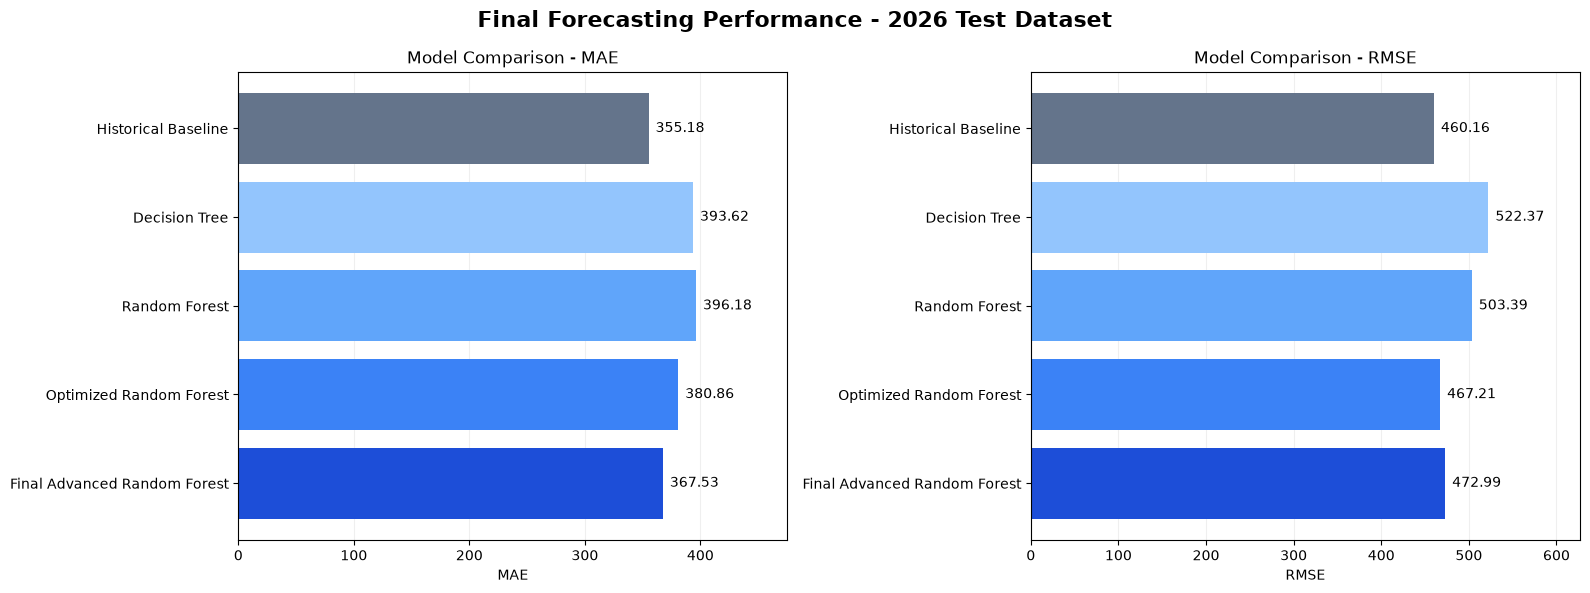

In [118]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = [
    "#64748B",
    "#93C5FD",
    "#60A5FA",
    "#3B82F6",
    "#1D4ED8"
]

for ax, metric in zip(axes, ["MAE", "RMSE"]):

    bars = ax.barh(
        final_test_results_df["Model"],
        final_test_results_df[metric],
        color=colors
    )

    ax.bar_label(bars, fmt="%.2f", padding=5)

    ax.set_title(f"Model Comparison - {metric}")
    ax.set_xlabel(metric)
    ax.set_xlim(
        0, final_test_results_df[metric].max() * 1.20
    )

    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    "Final Forecasting Performance - 2026 Test Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Actual vs. Predicted Sales Analysis

Compare actual sales with the predictions generated by
the historical baseline and the final advanced Random
Forest model.

This analysis helps identify how closely each forecasting
approach follows actual sales patterns, including sales
peaks, declines and fluctuations.

In [119]:
sales_comparison = pd.DataFrame({
    "Store": test_df["Store"].to_numpy(),
    "Date": test_df["Date"].to_numpy(),
    "Actual Sales": np.asarray(y_test),
    "Baseline Prediction": np.asarray(baseline_test_predictions),
    "Advanced RF Prediction": final_rf_test_predictions
})

sales_comparison["Baseline Absolute Error"] = abs(
    sales_comparison["Actual Sales"] -
    sales_comparison["Baseline Prediction"]
)

sales_comparison["Advanced RF Absolute Error"] = abs(
    sales_comparison["Actual Sales"] -
    sales_comparison["Advanced RF Prediction"]
)

sales_comparison.head(15).round(2)

/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_76227/2450742291.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  sales_comparison.head(15).round(2)


,Store,Date,Actual Sales,Baseline Prediction,Advanced RF Prediction,Baseline Absolute Error,Advanced RF Absolute Error
0,STR-1006,2026-03-01,2912.96,1408.53,1753.21,1504.43,1159.75
1,STR-1006,2026-03-02,1825.00,1042.29,1459.45,782.71,365.55
2,STR-1006,2026-03-03,1200.00,1089.43,1473.92,110.57,273.92
3,STR-1006,2026-03-04,2071.85,1298.65,1732.76,773.20,339.09
4,STR-1006,2026-03-05,1516.88,1550.32,1795.72,33.44,278.84
5,STR-1006,2026-03-06,2292.09,2004.48,2125.24,287.61,166.85
6,STR-1006,2026-03-07,1323.94,2440.69,2186.78,1116.75,862.84
7,STR-1006,2026-03-08,2348.10,1408.53,1631.18,939.57,716.92
8,STR-1006,2026-03-09,1367.94,1042.29,859.47,325.65,508.47
9,STR-1006,2026-03-10,1754.88,1089.43,978.64,665.45,776.24


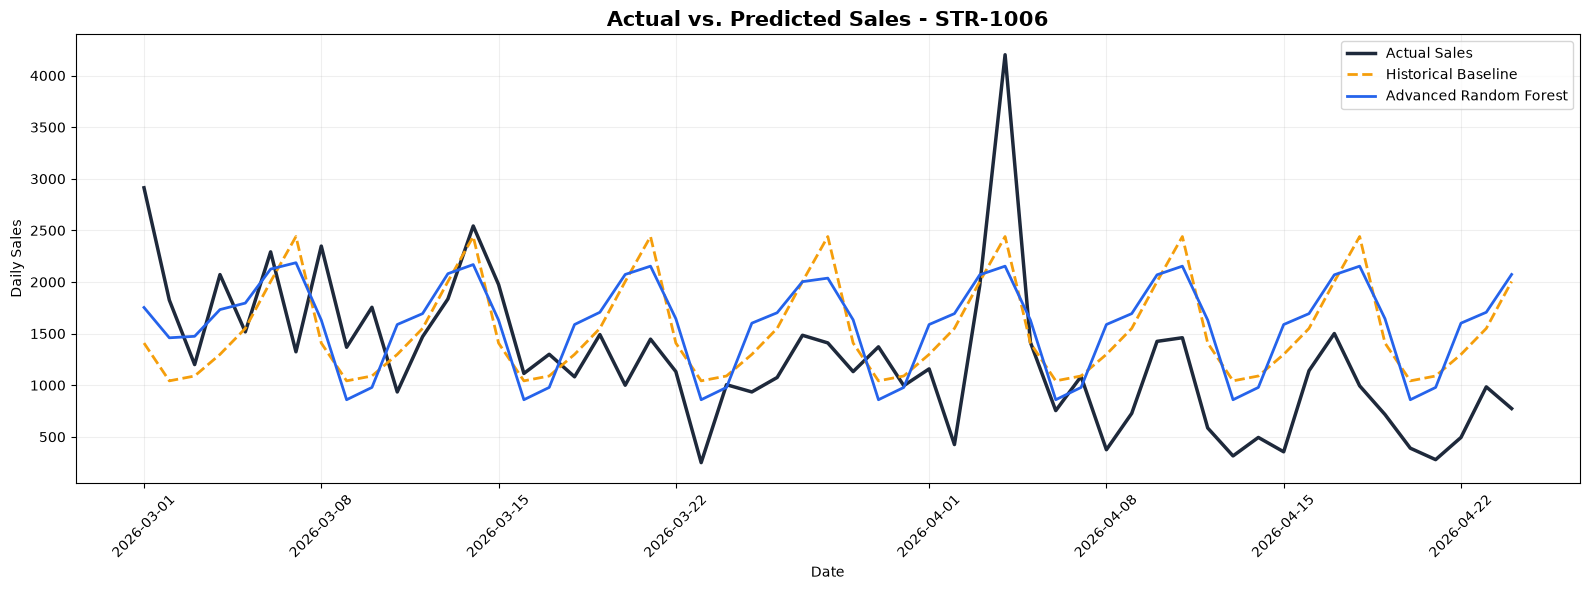

In [120]:
selected_store = "STR-1006"

store_comparison = sales_comparison[
    sales_comparison["Store"] == selected_store
].sort_values("Date")

plt.figure(figsize=(16, 6))

plt.plot(
    store_comparison["Date"],
    store_comparison["Actual Sales"],
    label="Actual Sales",
    color="#1E293B",
    linewidth=2.5
)

plt.plot(
    store_comparison["Date"],
    store_comparison["Baseline Prediction"],
    label="Historical Baseline",
    color="#F59E0B",
    linestyle="--",
    linewidth=2
)

plt.plot(
    store_comparison["Date"],
    store_comparison["Advanced RF Prediction"],
    label="Advanced Random Forest",
    color="#2563EB",
    linewidth=2
)

plt.title(
    f"Actual vs. Predicted Sales - {selected_store}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Prediction Error Analysis

Analyze the absolute prediction errors of the historical
baseline and the final advanced Random Forest model.

Compare error distributions, identify the largest
prediction errors and examine the limitations of
both forecasting approaches.

In [121]:
error_summary = pd.DataFrame({
    "Historical Baseline": 
        sales_comparison["Baseline Absolute Error"].describe(),

    "Advanced Random Forest":
        sales_comparison["Advanced RF Absolute Error"].describe()
})

error_summary.round(2)

,Historical Baseline,Advanced Random Forest
count,2150.00,2150.00
mean,355.18,367.53
std,292.63,297.80
min,0.04,0.43
25%,142.32,157.38
50%,291.75,310.48
75%,479.00,486.69
max,2353.06,2048.57


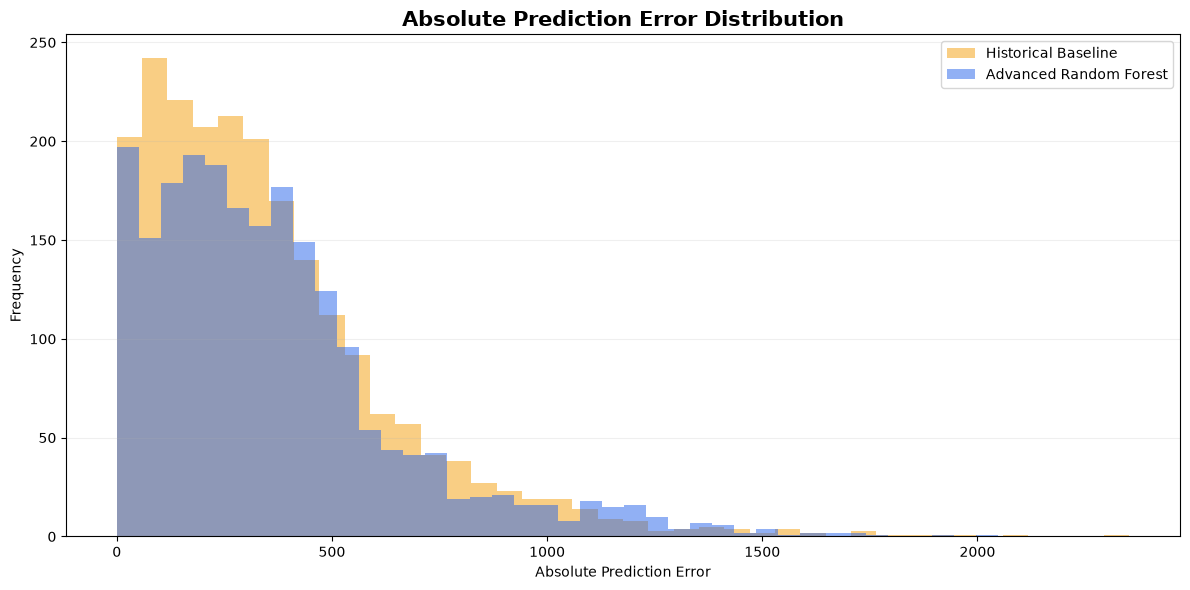

In [122]:
plt.figure(figsize=(12, 6))

plt.hist(
    sales_comparison["Baseline Absolute Error"],
    bins=40,
    alpha=0.5,
    color="#F59E0B",
    label="Historical Baseline"
)

plt.hist(
    sales_comparison["Advanced RF Absolute Error"],
    bins=40,
    alpha=0.5,
    color="#2563EB",
    label="Advanced Random Forest"
)

plt.title(
    "Absolute Prediction Error Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [123]:
largest_errors = sales_comparison.nlargest(
    10, "Advanced RF Absolute Error"
)

largest_errors.round(2)

/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_76227/4203978771.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  largest_errors.round(2)


,Store,Date,Actual Sales,Baseline Prediction,Advanced RF Prediction,Baseline Absolute Error,Advanced RF Absolute Error
34,STR-1006,2026-04-04,4202.05,2440.69,2153.48,1761.36,2048.57
878,STR-1148,2026-03-07,129.95,1898.40,2058.53,1768.45,1928.58
593,STR-1094,2026-04-18,389.44,2387.38,2153.48,1997.94,1764.04
473,STR-1082,2026-04-04,2721.91,1131.83,1000.03,1590.08,1721.88
1597,STR-1253,2026-04-04,439.96,2337.46,2153.48,1897.50,1713.52
1399,STR-1229,2026-04-17,323.98,1703.70,1994.32,1379.72,1670.34
69,STR-1010,2026-03-15,2364.58,965.67,703.92,1398.91,1660.66
1282,STR-1219,2026-04-03,2276.91,811.10,644.60,1465.81,1632.31
1711,STR-1305,2026-04-11,377.70,1690.65,1985.42,1312.95,1607.72
811,STR-1114,2026-04-18,452.99,1858.17,2005.84,1405.18,1552.85


#### Error Analysis Findings

Both forecasting approaches produce similar error distributions across the 2,150 test records.

The historical baseline achieves a slightly lower mean and median absolute error, while the Advanced
Random Forest reduces the maximum observed error by approximately 12.94%.

The largest prediction errors occur during unusually
high or low sales periods, indicating limitations
in predicting extreme sales fluctuations.

Although advanced feature engineering and model
optimization improved Random Forest performance,
the historical baseline remains the strongest
overall forecasting approach on this test dataset.

#### Feature Importance Analysis

Analyze the importance of the features used by the
Final Advanced Random Forest model.

Identify the most influential forecasting features
and examine the contribution of historical sales,
calendar information and advanced engineered features.

In [124]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train_advanced.columns,
    "Importance": final_advanced_rf.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(15)

,Feature,Importance
0,IsChristmasEve,0.331285
1,PastStoreWeekdayAvg,0.304161
2,RollingMean7,0.248547
3,IsChristmasSeason,0.041108
4,Month,0.027563
5,SalesLag7,0.026509
6,Day,0.011848
7,IsBlackFriday,0.004657
8,DayOfWeek,0.001845
9,RecentSalesTrend,0.001555


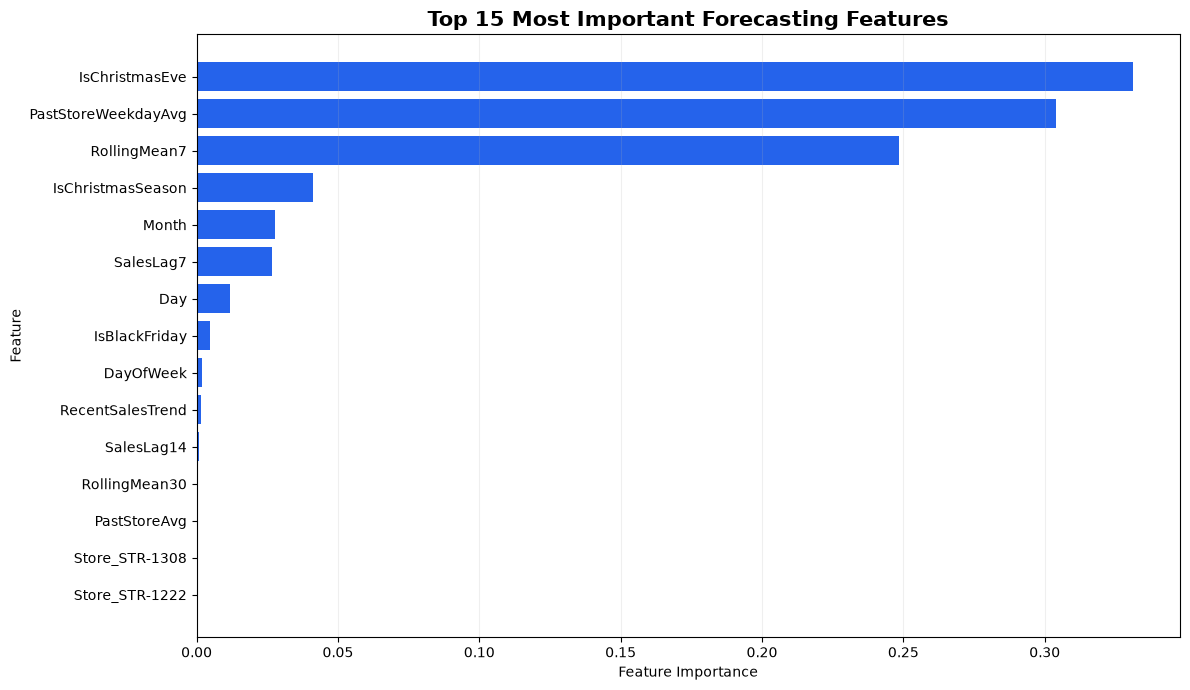

In [125]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(12, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="#2563EB"
)

plt.gca().invert_yaxis()

plt.title(
    "Top 15 Most Important Forecasting Features",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

#### Final Model Selection and Conclusion

Compare all forecasting approaches using their final
test MAE and RMSE results.

Identify the best-performing forecasting approach
and the best-performing machine learning model.

Evaluate whether hyperparameter optimization and
advanced feature engineering improved forecasting
performance compared to the original Random Forest.

In [129]:
best_overall_model = final_test_results_df.loc[
    final_test_results_df["MAE"].idxmin()
]

ml_models = final_test_results_df[
    final_test_results_df["Model"] != "Historical Baseline"
]

best_ml_model = ml_models.loc[
    ml_models["MAE"].idxmin()
]

print("Best overall forecasting approach:")
print(best_overall_model[["Model", "MAE", "RMSE"]])

print("\nBest machine learning model (by MAE):")
print(best_ml_model[["Model", "MAE", "RMSE"]])

Best overall forecasting approach:
Model    Historical Baseline
MAE               355.183577
RMSE              460.160789
Name: 0, dtype: object

Best machine learning model (by MAE):
Model    Final Advanced Random Forest
MAE                        367.533484
RMSE                       472.994431
Name: 4, dtype: object


In [128]:
original_rf_results = final_test_results_df.loc[
    final_test_results_df["Model"] == "Random Forest"
].iloc[0]

advanced_rf_results = final_test_results_df.loc[
    final_test_results_df["Model"] == "Final Advanced Random Forest"
].iloc[0]

mae_improvement = (
    (original_rf_results["MAE"] - advanced_rf_results["MAE"])
    / original_rf_results["MAE"] * 100
)

rmse_improvement = (
    (original_rf_results["RMSE"] - advanced_rf_results["RMSE"])
    / original_rf_results["RMSE"] * 100
)

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement: 7.23%
RMSE improvement: 6.04%


In [130]:
potential_leakage_features = [
    "Sales",
    "COGS",
    "GrossProfit",
    "QuantitySold",
    "Transactions",
    "ReturnRecords"
]

detected_features = [
    feature
    for feature in potential_leakage_features
    if feature in X_train_advanced.columns
]

print("Potential leakage features:", detected_features)

print("\nAll forecasting features:")
print(X_train_advanced.columns.tolist())

Potential leakage features: []

All forecasting features:
['DayOfWeek', 'Month', 'Day', 'Quarter', 'IsWeekend', 'IsChristmasSeason', 'IsChristmasEve', 'IsValentinesDay', 'IsBlackFriday', 'PastStoreAvg', 'PastStoreWeekdayAvg', 'Store_STR-1006', 'Store_STR-1010', 'Store_STR-1026', 'Store_STR-1038', 'Store_STR-1044', 'Store_STR-1074', 'Store_STR-1075', 'Store_STR-1080', 'Store_STR-1082', 'Store_STR-1085', 'Store_STR-1094', 'Store_STR-1105', 'Store_STR-1107', 'Store_STR-1109', 'Store_STR-1114', 'Store_STR-1145', 'Store_STR-1148', 'Store_STR-1149', 'Store_STR-1157', 'Store_STR-1163', 'Store_STR-1194', 'Store_STR-1198', 'Store_STR-1203', 'Store_STR-1219', 'Store_STR-1222', 'Store_STR-1229', 'Store_STR-1234', 'Store_STR-1235', 'Store_STR-1237', 'Store_STR-1253', 'Store_STR-1255', 'Store_STR-1305', 'Store_STR-1308', 'Store_STR-1335', 'Store_STR-1338', 'Store_STR-1344', 'Store_STR-1348', 'Store_STR-1350', 'Store_STR-1353', 'Store_STR-1369', 'SalesLag7', 'SalesLag14', 'RollingMean7', 'RollingMea

In [131]:
print("Training end:", train_df["Date"].max())
print("Validation start:", val_advanced["Date"].min())
print("Validation end:", val_advanced["Date"].max())
print("Test start:", test_df["Date"].min())

print("\nTraining and validation separated:",
      train_df["Date"].max() < val_advanced["Date"].min())

print("Validation and test separated:",
      val_advanced["Date"].max() < test_df["Date"].min())

print("\nHistorical data ends before test:",
      test_historical_sales["Date"].max() < test_df["Date"].min())

Training end: 2025-12-31 00:00:00
Validation start: 2026-01-01 00:00:00
Validation end: 2026-02-28 00:00:00
Test start: 2026-03-01 00:00:00

Training and validation separated: True
Validation and test separated: True

Historical data ends before test: True


#### Saving Forecasting Models

Save the trained forecasting models and their feature
configurations for future integration into the
BizInsight application.

In [132]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_advanced_rf,
    models_dir / "advanced_random_forest_2026.pkl"
)

joblib.dump(
    optimized_rf,
    models_dir / "optimized_random_forest_2026.pkl"
)

joblib.dump(
    X_train_advanced.columns.tolist(),
    models_dir / "advanced_features_2026.pkl"
)

joblib.dump(
    X_train.columns.tolist(),
    models_dir / "original_features_2026.pkl"
)

print("Models and feature configurations saved successfully.")

Models and feature configurations saved successfully.


In [133]:
for file in models_dir.glob("*2026.pkl"):
    print(file.name)

advanced_random_forest_2026.pkl
optimized_random_forest_2026.pkl
advanced_features_2026.pkl
original_features_2026.pkl


#### Saved Model Verification

Load the saved forecasting model and feature configuration.
Verify that the loaded model produces identical predictions
to the original trained model.

In [134]:
loaded_advanced_rf = joblib.load(
    models_dir / "advanced_random_forest_2026.pkl"
)

loaded_advanced_features = joblib.load(
    models_dir / "advanced_features_2026.pkl"
)

loaded_predictions = loaded_advanced_rf.predict(
    X_test_advanced[loaded_advanced_features]
)

print("Model loaded successfully.")

print("Number of features:",
      len(loaded_advanced_features))

print("Predictions generated:",
      len(loaded_predictions))

print("Predictions match:",
      np.allclose(
          loaded_predictions,
          final_rf_test_predictions
      ))

Model loaded successfully.
Number of features: 56
Predictions generated: 2150
Predictions match: True


#### Save Historical Forecasting Data

Save the historical sales records required for calculating
historical averages, lag features and rolling sales statistics
during future forecasting.

In [135]:
joblib.dump(
    test_historical_sales,
    models_dir / "historical_sales_2026.pkl"
)

loaded_history = joblib.load(
    models_dir / "historical_sales_2026.pkl"
)

print("Historical data saved successfully.")
print("Historical records:", len(loaded_history))
print("Number of stores:", loaded_history["Store"].nunique())
print("Last historical date:", loaded_history["Date"].max())

Historical data saved successfully.
Historical records: 10276
Number of stores: 40
Last historical date: 2026-02-28 00:00:00


#### Reusable Sales Forecasting Function

Create a reusable forecasting function that loads the saved
machine learning model and feature configuration, validates
the input features and generates sales predictions.

Verify that the function reproduces the previously evaluated
test predictions.

In [136]:
def predict_sales_2026(input_features):
    model = joblib.load(
        models_dir / "advanced_random_forest_2026.pkl"
    )

    features = joblib.load(
        models_dir / "advanced_features_2026.pkl"
    )

    missing_features = [
        feature for feature in features
        if feature not in input_features.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    X = input_features[features].copy()

    if X.isnull().any().any():
        raise ValueError("Input contains missing values.")

    predictions = model.predict(X)

    return np.maximum(predictions, 0)

In [137]:
reusable_predictions = predict_sales_2026(
    X_test_advanced
)

print("Forecasting function executed successfully.")

print("Predictions generated:",
      len(reusable_predictions))

print("Predictions match:",
      np.allclose(
          reusable_predictions,
          final_rf_test_predictions
      ))

Forecasting function executed successfully.
Predictions generated: 2150
Predictions match: True
